# **Analysis and Preprocessing of Amazon Saies Data**

The Amazon Sales dataset represents a structured and comprehensive collection of product-related information, including pricing, discount rates, and customer-generated ratings.

This project aims not only to preprocess and clean the data, but also to explore key patterns and relationships within the dataset. Specifically, the analysis focuses on understanding the distribution of product ratings, evaluating whether ratings reflect customer satisfaction, and examining the relationship between pricing features (such as actual price and discounted price) and product performance.

In addition, the project investigates the reliability of ratings by incorporating features such as rating count and rating credibility, helping to assess whether highly rated products are truly trustworthy. Feature relationships are further analyzed using correlation and dimensionality reduction techniques such as PCA, allowing the identification of the most influential factors in the dataset.

The ultimate goal is to transform raw data into meaningful insights that explain customer behavior, product quality, and pricing strategies.

Description of the variables of the data used here .



* **product_id**: A unique identifier for each product.
* **product_name**: The name of the product.
* **category**: The category to which the product belongs.
* **discounted_price**: The price of the product after applying the discount.
* **actual_price**: The original price of the product before discount.
* **discount_percentage**: The percentage discount applied to the product.
* **rating**: The average customer rating of the produc
* **rating_count**: The number of customers who rated the product
* **about_product**: A brief description of the product.
* **user_id**: A unique identifier for the user.
* **user_name**: The name of the user who provided the review.
* **review_id**: A unique identifier for each review.

*  **review_title**: The title of the product review.


*   **review_content**: The content of the customer review.
*   **img_link**: The link to the product image.
*   **product_link**: The link to the product page on Amazon.






---



**Student:**

Reham Mohammed

**ID:** 446000359

Amira Abdulrahim Al-huzali

**ID:** 446008078

Asmaa khalid Al akbari

**ID**: 446000160

Lamar Mohammed Al-ghamdi

**ID**:446002942

________________________________________________________________________________________________________________________________________________________________



---


#**Section 1.** Data Load & inspection


---






#**Import libraries**



In [ ]:
# استيراد المكتبات / Import libraries
import pandas as pd  # معالجة الجداول / Data manipulation
import numpy as np  # العمليات الرياضية / Math operations
import matplotlib.pyplot as plt  # رسم البياني / Plotting charts
import seaborn as sns  # رسم إحصائي / Statistical plots
from sklearn.linear_model import LinearRegression  # انحدار خطي / Linear regression
from sklearn.feature_selection import RFE  # اختيار الميزات / Feature selection
from sklearn.preprocessing import StandardScaler  # تطبيع البيانات / Data normalization
from sklearn.decomposition import PCA  # تقليل الأبعاد / Dimension reduction



##**1.Load the Amazon**


In [ ]:
# تحميل البيانات / Load dataset
df = pd.read_csv("amazon.csv")

**Explanation**  
The dataset was loaded using the pandas library.  
تم تحميل البيانات باستخدام مكتبة



### **2. Preview Data**

In [ ]:
# عرض أول 5 صفوف / Preview first 5 rows
df.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


**Explanation**  

The head() function displays the first 5 rows of the dataset to understand its structure.

تعرض دالة head() أول 5 صفوف لفهم شكل البيانات.

## 3. Dataset Shape

In [ ]:
# عرض عدد الصفوف والأعمدة / Show shape
df.shape

(1465, 16)

**Explanation**  
The shape function shows the number of rows and columns in the dataset.  
تعرض دالة shape عدد الصفوف والأعمدة في البيانات.





### 4. Column Names

In [ ]:
# عرض أسماء الأعمدة / Show columns
df.columns

Index(['product_id', 'product_name', 'category', 'discounted_price',
       'actual_price', 'discount_percentage', 'rating', 'rating_count',
       'about_product', 'user_id', 'user_name', 'review_id', 'review_title',
       'review_content', 'img_link', 'product_link'],
      dtype='object')

**Explanation**  
The columns function lists all column names in the dataset.  
تعرض دالة columns جميع أسماء الأعمدة في البيانات.

### 5. Data Information

In [ ]:
# عرض معلومات البيانات / Show info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   product_id           1465 non-null   object
 1   product_name         1465 non-null   object
 2   category             1465 non-null   object
 3   discounted_price     1465 non-null   object
 4   actual_price         1465 non-null   object
 5   discount_percentage  1465 non-null   object
 6   rating               1465 non-null   object
 7   rating_count         1463 non-null   object
 8   about_product        1465 non-null   object
 9   user_id              1465 non-null   object
 10  user_name            1465 non-null   object
 11  review_id            1465 non-null   object
 12  review_title         1465 non-null   object
 13  review_content       1465 non-null   object
 14  img_link             1465 non-null   object
 15  product_link         1465 non-null   object
dtypes: obj

**Explanation**  
The info() function provides information about data types and missing values.  
تعرض دالة info() أنواع البيانات والقيم الناقصة.

**Observation**


Most columns have no missing values, and all columns are of type object. This indicates that some numerical columns need to be converted into numeric data types.

الملاحظات الأولية

معظم الأعمدة لا تحتوي على قيم مفقودة، وجميع الأعمدة من نوع object، وهذا يدل على ضرورة تحويل بعض الأعمدة إلى نوع رقمي.

## 6. Statistical Summary

In [ ]:
# عرض الإحصائيات / Show statistics
df.describe()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
count,1465,1465,1465,1465,1465,1465,1465,1463,1465,1465,1465,1465,1465,1465,1465,1465
unique,1351,1337,211,550,449,92,28,1143,1293,1194,1194,1194,1194,1212,1412,1465
top,B083342NKJ,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",Computers&Accessories|Accessories&Peripherals|...,₹199,₹999,50%,4.1,"9,378",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AHIKJUDTVJ4T6DV6IUGFYZ5LXMPA,AE55KTFVNXYFD5FPY...","$@|\|TO$|-|,Sethu madhav,Akash Thakur,Burger P...","R3F4T5TRYPTMIG,R3DQIEC603E7AY,R1O4Z15FD40PV5,R...","Worked on iPhone 7 and didn’t work on XR,Good ...","I am not big on camera usage, personally. I wa...",https://m.media-amazon.com/images/I/413sCRKobN...,https://www.amazon.in/Borosil-Jumbo-1000-Watt-...
freq,3,5,233,53,120,56,244,9,6,10,10,10,10,8,3,1


Explanation

The describe() function was used to summarize the dataset.  
Since most columns are stored as object data type, the output shows categorical statistics such as count, unique, top, and frequency instead of numerical measures.

تم استخدام دالة describe() لتلخيص البيانات.  
وبما أن معظم الأعمدة مخزنة كنوع نصي (object)، فإن الناتج يعرض إحصائيات نصية مثل عدد القيم والقيم الفريدة والأكثر تكرارًا بدلاً من القيم الرقمية.


### Initial Observations

From the initial inspection, we can understand the general structure of the dataset, including the number of rows, columns, and variable types.

The dataset contains multiple columns related to products, such as pricing, categories, and customer information.

The describe() output shows categorical statistics such as count, unique values, most frequent value, and frequency.

### الملاحظات الأولية

من خلال الفحص الأولي، يمكن فهم شكل البيانات مثل عدد الصفوف والأعمدة وأنواع المتغيرات.

تحتوي البيانات على عدة أعمدة متعلقة بالمنتجات مثل الأسعار والفئات ومعلومات العملاء.

ناتج describe() يعرض إحصائيات نصية مثل عدد القيم والقيم الفريدة وأكثر القيم تكرارًا.








---








---


# **Section 2: Data Quality Assessment**


---



### 1. Missing Values

In [ ]:
# حساب القيم الناقصة / Check missing values
df.isnull().sum()

,0
product_id,0
product_name,0
category,0
discounted_price,0
actual_price,0
discount_percentage,0
rating,0
rating_count,2
about_product,0
user_id,0


In [ ]:
# تخزين عدد القيم المفقودة في متغير | Store missing values count in a variable
missing_value = df.isnull().sum()

In [ ]:
# عرض الأعمدة التي تحتوي على قيم مفقودة فقط | Display columns that have missing values only
missing_values = missing_value[missing_value > 0]
missing_values

,0
rating_count,2


Explanation

First, the code calculates and displays the number of missing values in each column using df.isnull().sum().  
Then, the result is stored in a variable called missing_value.  
After that, the code filters and displays only the columns that contain missing values.

أولًا، يقوم الكود بحساب وعرض عدد القيم الناقصة في كل عمود باستخدام df.isnull().sum().  
بعد ذلك، يتم تخزين النتيجة في متغير باسم missing_value.  
ثم يتم تصفية وعرض الأعمدة التي تحتوي فقط على قيم ناقصة.

Observation

The result shows that only the rating_count column contains missing values, with 2 missing entries, while all other columns have no missing values.

توضح النتيجة أن عمود rating_count فقط يحتوي على قيم ناقصة وعددها قيمتان، بينما باقي الأعمدة لا تحتوي على قيم ناقصة.

### 2. Duplicate Records

In [ ]:
# التحقق من التكرار / Check duplicates
df.duplicated().sum()

np.int64(0)

**Explanation**  
This code checks for duplicate rows in the dataset.  
هذا الكود يتحقق من الصفوف المكررة في البيانات.

**Observation**  
No duplicate records were found in the dataset.  
لم يتم العثور على أي صفوف مكررة في البيانات.

This means the dataset does not contain redundancy issues.

وهذا يعني أن البيانات لا تحتوي على مشاكل تكرار.

### 3. Inconsistent Labels

In [ ]:
# عرض القيم الفريدة / Check unique values
df['category'].unique()

array(['Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables',
       'Computers&Accessories|NetworkingDevices|NetworkAdapters|WirelessUSBAdapters',
       'Electronics|HomeTheater,TV&Video|Accessories|Cables|HDMICables',
       'Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions',
       'Electronics|HomeTheater,TV&Video|Accessories|RemoteControls',
       'Electronics|HomeTheater,TV&Video|Televisions|StandardTelevisions',
       'Electronics|HomeTheater,TV&Video|Accessories|TVMounts,Stands&Turntables|TVWall&CeilingMounts',
       'Electronics|HomeTheater,TV&Video|Accessories|Cables|RCACables',
       'Electronics|HomeAudio|Accessories|SpeakerAccessories|Mounts',
       'Electronics|HomeTheater,TV&Video|Accessories|Cables|OpticalCables',
       'Electronics|HomeTheater,TV&Video|Projectors',
       'Electronics|HomeAudio|Accessories|Adapters',
       'Electronics|HomeTheater,TV&Video|SatelliteEquipment|SatelliteReceivers',
       'Computers&Acces

**Explanation**  
This code displays all unique values in the "category" column.  
هذا الكود يعرض جميع القيم الفريدة في عمود الفئات.

**Observation**  
The dataset contains many different categories, and the values are written in a hierarchical format separated by "|".  
البيانات تحتوي على عدد كبير من الفئات المختلفة، والقيم مكتوبة بشكل هرمي باستخدام الرمز "|".

This may cause inconsistency during analysis and may require cleaning or splitting into multiple columns.

قد يسبب ذلك عدم تناسق أثناء التحليل وقد يحتاج إلى تنظيف أو تقسيم إلى أعمدة متعددة.


### 4.Temporary Conversion for Validation

In [ ]:
# تحويل مؤقت للأعمدة الرقمية لفحص القيم غير الصالحة
# Temporary conversion for validation only
cols_to_convert = ['discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count']

for col in cols_to_convert:
    df[col] = df[col].astype(str)  # تحويل لنص / convert to string
    df[col] = df[col].str.replace('₹', '', regex=False)  # حذف العملة / remove currency
    df[col] = df[col].str.replace(',', '', regex=False)  # حذف الفواصل / remove commas
    df[col] = df[col].str.replace('%', '', regex=False)  # حذف النسبة / remove %
    df[col] = pd.to_numeric(df[col], errors='coerce')  # تحويل لأرقام / convert to numeric

Explanation

This code temporarily converts some columns into numeric values by removing symbols like currency signs, commas, and percentage symbols.

This is done only to allow checking for invalid values (such as negative or out-of-range values), since these checks require numeric data.

هذا الكود يحول بعض الأعمدة إلى أرقام بشكل مؤقت بعد إزالة الرموز مثل العملة والفواصل وعلامة النسبة المئوية.

تم ذلك فقط لتمكين فحص القيم غير الصحيحة، لأن هذا النوع من الفحص يحتاج بيانات رقمية.


Observation

After the conversion, the selected columns became suitable for checking invalid values.

This means the data is now ready for validation without applying final cleaning.

بعد التحويل، أصبحت الأعمدة المختارة مناسبة لفحص القيم غير الصحيحة.

وهذا يعني أن البيانات أصبحت جاهزة للفحص بدون إجراء تنظيف نهائي.

### 5. Invalid Values



In [ ]:

# تحديد الأعمدة الرقمية / Select all numeric columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

# 1. فحص القيم السالبة / Check negative values
print("Negative Values:")
for col in num_cols:
    count_neg = (df[col] < 0).sum()
    print(f"{col}: {count_neg}")

# 2. فحص القيم غير الممكنة / Check impossible values
print("\nImpossible Values:")

# rating (should be between 0 and 5)
if 'rating' in df.columns:
    invalid_rating = ((df['rating'] < 0) | (df['rating'] > 5)).sum()
    print(f"rating out of range (0-5): {invalid_rating}")

# discount_percentage (should be between 0 and 100)
if 'discount_percentage' in df.columns:
    invalid_discount = ((df['discount_percentage'] < 0) | (df['discount_percentage'] > 100)).sum()
    print(f"discount_percentage out of range (0-100): {invalid_discount}")

# rating_count (should not be negative)
if 'rating_count' in df.columns:
    invalid_count = (df['rating_count'] < 0).sum()
    print(f"rating_count negative values: {invalid_count}")

Negative Values:
discounted_price: 0
actual_price: 0
discount_percentage: 0
rating: 0
rating_count: 0

Impossible Values:
rating out of range (0-5): 0
discount_percentage out of range (0-100): 0
rating_count negative values: 0


**Explanation**

This code checks all numeric columns for invalid values such as negative numbers.
It also verifies specific columns to ensure values fall within logical ranges, such as rating (0–5) and discount percentage (0–100).

هذا الكود يفحص جميع الأعمدة الرقمية لاكتشاف القيم غير الصالحة مثل القيم السالبة،
كما يتحقق من القيم المنطقية مثل التقييم (من 0 إلى 5) ونسبة الخصم (من 0 إلى 100).

**Observation**

The results show that all values are valid, as no negative or out-of-range values were found in the dataset.

النتائج توضح أن جميع القيم صحيحة، حيث لم يتم العثور على قيم سالبة أو غير منطقية في البيانات.

### 6. Data Types

In [ ]:
# عرض أنواع البيانات / Check data types
df.dtypes

,0
product_id,object
product_name,object
category,object
discounted_price,object
actual_price,object
discount_percentage,object
rating,object
rating_count,object
about_product,object
user_id,object


**Explanation**:
This code displays the data type of each column in the dataset.  
هذا الكود يعرض نوع البيانات لكل عمود في البيانات.
_________________________________


### Final Observations

From the data quality assessment, the dataset is generally clean with no duplicate records and no invalid (negative or out-of-range) values detected.

However, 2 missing values were found in the "rating_count" column.

The "category" column contains hierarchical values separated by "|" which may lead to inconsistency during analysis.

In addition, some columns were stored with incorrect data types (numeric columns stored as object).


# الملاحظات النهائية

من خلال تقييم جودة البيانات، يتضح أن البيانات نظيفة بشكل عام ولا تحتوي على سجلات مكررة أو قيم غير صحيحة (سالبة أو خارج النطاق).

تم العثور على قيمتين ناقصتين في عمود "rating_count".

عمود "category" يحتوي على قيم هرمية مفصولة بالرمز "|" مما قد يسبب عدم اتساق أثناء التحليل.

كما تم ملاحظة أن بعض الأعمدة مخزنة بنوع بيانات غير صحيح (نص بدل رقم).



---





---


# **Section 3:** Data Cleaning & Exploratory Data Analysis (EDA)


---



## **A. Data cleaning**

### **1. Fix Data Type**

#### Convert columns

In [ ]:
# Clean and convert columns to numeric format

# discounted_price: remove currency symbol and commas, then convert to numeric
# السعر بعد الخصم: إزالة رمز العملة والفواصل ثم التحويل إلى رقم
df['discounted_price'] = pd.to_numeric(
    df['discounted_price'].astype(str)
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False),
    errors='coerce'
)

# actual_price: remove currency symbol and commas, then convert to numeric
# السعر الأصلي: إزالة رمز العملة والفواصل ثم التحويل إلى رقم
df['actual_price'] = pd.to_numeric(
    df['actual_price'].astype(str)
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False),
    errors='coerce'
)

# discount_percentage: remove % sign, then convert to numeric
# نسبة الخصم: إزالة علامة % ثم التحويل إلى رقم
df['discount_percentage'] = pd.to_numeric(
    df['discount_percentage'].astype(str)
    .str.replace('%', '', regex=False),
    errors='coerce'
)

# rating: convert directly to numeric
# التقييم: تحويل مباشر إلى رقم
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')

# rating_count: remove commas, then convert to numeric
# عدد التقييمات: إزالة الفواصل ثم التحويل إلى رقم
df['rating_count'] = pd.to_numeric(
    df['rating_count'].astype(str)
    .str.replace(',', '', regex=False),
    errors='coerce'
)


**Explanation**:

The code cleans and converts important columns into numeric format by removing symbols such as currency signs, commas, and percentage symbols.  
Then, missing values in the rating and rating_count columns are handled using the median to avoid data loss.


بعد التنظيف، تم تحويل الأعمدة إلى نوع بيانات رقمي بنجاح، مما يسمح بإجراء تحليل دقيق.  


### **2 . Handling Missing Value**

In [ ]:
df.isnull().sum()

,0
product_id,0
product_name,0
category,0
discounted_price,0
actual_price,0
discount_percentage,0
rating,1
rating_count,2
about_product,0
user_id,0


**Explanation**:

We displayed the dataset before handling missing values to identify where missing data exists.

 قمنا بعرض البيانات قبل معالجة القيم المفقودة لتحديد أماكن القيم الناقصة.

**Observation**


 We noticed missing values specifically in the 'rating_count' column during data inspection.

  لاحظنا وجود قيم مفقودة تحديدًا في عمود عدد التقييمات (rating_count) أثناء استكشاف البيانات.


####Method 1:  Fill Using Median


In [ ]:

# Fill Using Median
df['rating_count'] = df['rating_count'].fillna(df['rating_count'].median())
df['rating'] = df['rating'].fillna(df['rating'].median())


**Explanation**:
We handled missing values using the median because it is more robust to outliers.

 قمنا بمعالجة القيم المفقودة باستخدام الوسيط لأنه أقل تأثرًا بالقيم الشاذة.

 The dataset contains extreme values, so using the mean could distort the data.

 تحتوي البيانات على قيم متطرفة، لذلك استخدام المتوسط الحسابي قد يشوه النتائج.


 The median provides a better representation of the central tendency and keeps the data more stable.

 الوسيط يعطي تمثيلًا أفضل للقيمة المركزية ويحافظ على استقرار البيانات.


 This approach allows us to fill missing values without significantly affecting the overall distribution.

 هذه الطريقة تسمح لنا بتعويض القيم المفقودة بدون التأثير الكبير على توزيع البيانات٨



#### Method 2 : Drop row

In [ ]:
#removed rows with missing values
#df_drop = df.dropna()


**Explanation**:

 We removed rows with missing values`to keep only complete data.

 حذفنا الصفوف التي تحتوي على قيم ناقصة للحصول على بيانات نظيفة.


**Comparison**

	•	Median keeps all data but may slightly distort values
	•	Dropping removes data but ensures accuracy

	•	التعويض بالوسيط يحافظ على البيانات لكن قد يغيّر القيم قليلاً
	•	الحذف يعطي دقة أعلى لكن يقلل حجم البيانات



##### **Final Choice**

 **Median** was chosen to avoid losing data.

 اخترنا الوسيط لتجنب فقدان البيانات.


In [ ]:
# missing values are now handled
# تم معالجة القيم المفقودة
df.isnull().sum()

,0
product_id,0
product_name,0
category,0
discounted_price,0
actual_price,0
discount_percentage,0
rating,0
rating_count,0
about_product,0
user_id,0


### **3. Remove Duplicates**

In [ ]:
# Remove Duplicates
df = df.drop_duplicates()


**Explanation**:


 we doun't have duplicats

 فقط طبقنا كود الحذف ولكن لا يوجد لدينا تكرار

### **4. Fix Additional Data Quality Issues**

#### Clean category

In [ ]:
df['category'] = df['category'].str.split('|').str[0]

**Explanation**:

 This code simplifies the "category" column by splitting the hierarchical values using "|" and keeping only the main category.  
This helps make the data more consistent and easier to analyze.

يقوم هذا الكود بتبسيط عمود "category" عن طريق تقسيم القيم الهرمية باستخدام الرمز "|" والاحتفاظ بالفئة الرئيسية فقط.  
هذا يساعد في جعل البيانات أكثر تنظيمًا وأسهل في التحليل.

_________________________________
**Observation**:

The symbols were already removed in the previous step during data type conversion, so no additional cleaning was needed here.


 تم إزالة الرموز في الخطوة السابقة أثناء تحويل أنواع البيانات، لذلك لا حاجة لتنظيف إضافي هنا.


In [ ]:
df.dtypes

,0
product_id,object
product_name,object
category,object
discounted_price,float64
actual_price,float64
discount_percentage,int64
rating,float64
rating_count,float64
about_product,object
user_id,object


In [ ]:
df.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link,mid_category
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories,399.0,1099.0,64,4.2,24269.0,High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,Computers&Accessories
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories,199.0,349.0,43,4.0,41526.0,"Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...,Computers&Accessories
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories,199.0,1899.0,90,3.9,7928.0,【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...,Computers&Accessories
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories,329.0,699.0,53,4.2,41526.0,The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...,Computers&Accessories
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories,154.0,399.0,61,4.2,16905.0,[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...,Computers&Accessories


After cleaning
بعد التنظيف

## **B. Exploratory Data Analysis (EDA)**

In [ ]:
# Using the cleaned dataset from Section 3A
# استخدام البيانات بعد التنظيف من Section 3A

# Extract middle-level category to avoid overly general or overly specific categories
# استخراج الفئة من المستوى الأوسط (لتجنب التعميم أو التخصيص الزائد)
df['mid_category'] = df['category'].apply(
    lambda x: str(x).split('|')[2] if '|' in str(x) and len(str(x).split('|')) > 2 else str(x)
)

# Select top 10 most frequent middle categories to reduce noise
# اختيار أكثر 10 فئات ظهوراً لتقليل التشتت
top_categories = df['mid_category'].value_counts().head(10)

filtered_data = df[
    df['mid_category'].isin(top_categories.index)
]

**Explanation:**

The original category column was hierarchical and very detailed.

Using the middle-level category provides a more balanced analysis.
The first level is too general and groups many unrelated products together, while the last level is too specific and creates excessive fragmentation.

Selecting the middle level helps reduce bias and ensures that categories are neither overly broad nor overly detailed, improving the reliability and interpretability of the analysis.


كان عمود الفئة الأصلي هرميًا ومفصّلًا للغاية.

استخدام مستوى الفئة المتوسطة يوفّر تحليلًا أكثر توازنًا.
المستوى الأول عام جدًا ويجمع منتجات غير مرتبطة معًا، بينما المستوى الأخير محدد جدًا ويؤدي إلى تجزئة مفرطة.

اختيار المستوى المتوسط يساعد في تقليل الانحياز ويضمن أن الفئات ليست واسعة جدًا ولا دقيقة جدًا، مما يحسّن من موثوقية التحليل وسهولة تفسيره.

**• Additionally, selecting the top 10 most frequent categories helps reduce noise from less represented categories and ensures that the analysis focuses on the most significant and reliable groups.**

### **1. Summary Statistics**

In [ ]:
# الإحصائيات العامة| General statistical summary
filtered_data.describe()

# Category frequency
filtered_data['mid_category'].value_counts()


,count
mid_category,
Electronics,526
Computers&Accessories,453
Home&Kitchen,448
OfficeProducts,31
MusicalInstruments,2
HomeImprovement,2
Toys&Games,1
Car&Motorbike,1
Health&PersonalCare,1


**Explanation:**

*describe()* gives a statistical summary of numerical variables.

*value_counts()* helps identify the most dominant categories.


---


*describe()* يعرض ملخصًا إحصائيًا للمتغيرات الرقمية

*value_counts()* يساعد في معرفة أكثر الفئات انتشارًا في البيانات

#### Observation (Category Distribution):

The results show that Electronics is the most common category, followed by Computers & Accessories and Home & Kitchen.

This indicates that the dataset is highly concentrated in a few dominant categories, particularly technology-related products.

This imbalance in category distribution may bias the analysis results, as categories with more data have a stronger influence on overall patterns compared to less represented categories.

تُظهر النتائج أن فئة Electronics هي الأكثر انتشارًا، تليها Computers & Accessories ثم Home & Kitchen.

يشير هذا إلى أن مجموعة البيانات مركّزة بشكل كبير في عدد قليل من الفئات المهيمنة، ولا سيما المنتجات المتعلقة بالتكنولوجيا.

هذا الاختلال في توزيع الفئات قد يُحيز نتائج التحليل، إذ تمتلك الفئات ذات البيانات الأكثر تأثيراً أقوى على الأنماط العامة مقارنةً بالفئات الأقل تمثيلاً.

### **2. Data Aggregation**

In [ ]:
# Average rating for each category متوسط التقييم لكل فئة
avg_rating = filtered_data.groupby('mid_category')['rating'].mean()
avg_rating

# Average discounted price for each category متوسط السعر بعد الخصم لكل فئة
avg_price = filtered_data.groupby('mid_category')['discounted_price'].mean()
avg_price

# Pivot Table
pivot_table = filtered_data.pivot_table(
    values=['rating', 'discounted_price', 'discount_percentage'],
    index='mid_category',
    aggfunc='mean'
).round(2)
pivot_table

,discount_percentage,discounted_price,rating
mid_category,,,
Car&Motorbike,42.00,2339.00,3.80
Computers&Accessories,54.02,842.65,4.15
Electronics,50.83,5965.89,4.08
Health&PersonalCare,53.00,899.00,4.00
Home&Kitchen,40.12,2330.62,4.04
HomeImprovement,57.50,337.00,4.25
MusicalInstruments,46.00,638.00,3.90
OfficeProducts,12.35,301.58,4.31
Toys&Games,0.00,150.00,4.30


**Explanation:**

*groupby()* was used to compare categories based on average rating and price.

*pivot_table()* gives a clearer summary of multiple values for each category.

استخدمنا *groupby()* لمقارنة الفئات حسب متوسط التقييم والسعر

واستخدمنا *pivot_table()* لعرض أكثر من قيمة لكل فئة بشكل منظم.

#### Observation (Aggregation Results)

The aggregation results show that product performance varies across categories.  
Some categories have higher average ratings than others, indicating differences in customer satisfaction.

For example, HomeImprovement recorded the highest average rating (4.25), while Car & Motorbike recorded the lowest (3.80).

Pricing also differs significantly between categories, suggesting that each product group follows a different pricing strategy.

Overall, aggregation helps identify which categories perform better in terms of rating and pricing behavior.


أظهرت نتائج التجميع أن أداء المنتجات يختلف بين الفئات.  
بعض الفئات حصلت على متوسط تقييم أعلى من غيرها، مما يدل على اختلاف رضا العملاء بين الفئات.

على سبيل المثال، سجلت فئة HomeImprovement أعلى متوسط تقييم (4.25)، بينما سجلت فئة Car & Motorbike أدنى متوسط (3.80).

كما يوجد اختلاف واضح في الأسعار بين الفئات، مما يشير إلى أن كل فئة تتبع استراتيجية تسعير مختلفة.

بشكل عام، ساعدنا التجميع في تحديد الفئات الأفضل من ناحية التقييم وسلوك الأسعار.

### **3. Histogram: Distribution of Ratings**

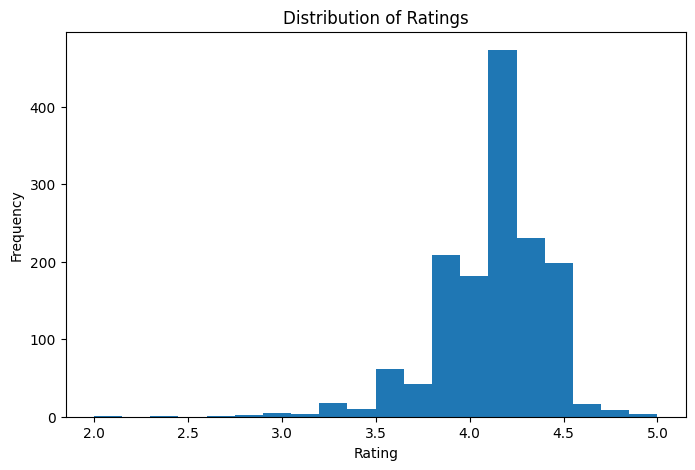

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(filtered_data['rating'], bins=20)

plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

This visualization shows the distribution of product ratings.  
Most ratings are concentrated between 4 and 5, indicating that most products receive high customer satisfaction scores.

Lower ratings are relatively rare, which suggests that overall customer feedback is generally positive.


يوضح هذا الرسم توزيع تقييمات المنتجات.  
نلاحظ أن أغلب التقييمات تقع بين 4 و5، مما يدل على رضا العملاء بشكل عام.

كما أن التقييمات المنخفضة قليلة، وهذا يشير إلى أن آراء العملاء غالبًا إيجابية.

### **4. Box Plot: Discounted Price**

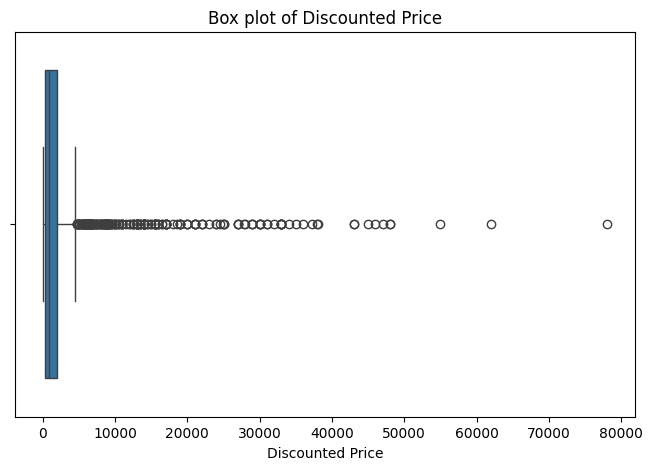

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(x=filtered_data['discounted_price'])

plt.title("Box plot of Discounted Price")
plt.xlabel("Discounted Price")
plt.show()

This visualization shows the distribution of discounted prices and highlights the presence of outliers.

Most products are concentrated within a lower price range, while some products have much higher prices.

This indicates that product prices vary widely across the dataset.


يوضح هذا الرسم توزيع الأسعار بعد الخصم ووجود بعض القيم المتطرفة.

نلاحظ أن أغلب المنتجات تقع ضمن نطاق سعري منخفض، بينما توجد بعض المنتجات بأسعار مرتفعة جدًا.

وهذا يدل على وجود تفاوت واضح في أسعار المنتجات.

### **5. Bar Plot**

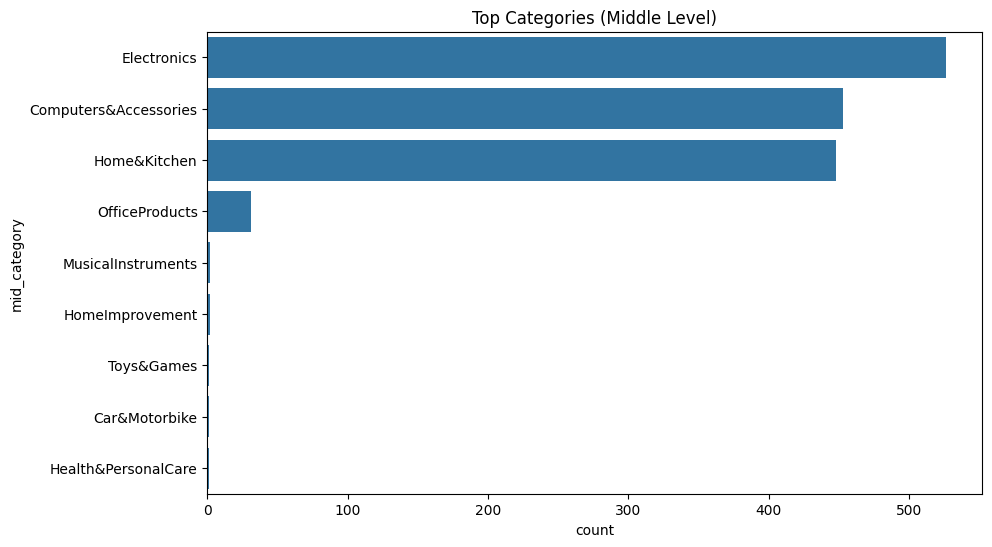

In [ ]:
plt.figure(figsize=(10,6))

sns.countplot(
    y='mid_category',
    data=filtered_data,
    order=filtered_data['mid_category'].value_counts().index
)

plt.title("Top Categories (Middle Level)")
plt.show()


This visualization shows the most frequent middle-level categories in the dataset.

Electronics appears as the most common category, followed by Computers & Accessories and Home & Kitchen.

This indicates that the dataset is mainly concentrated in a few dominant categories.

This imbalance may bias the analysis toward these dominant categories, making the results less representative of smaller categories. Therefore, conclusions may be influenced more by the characteristics of these major categories.


يوضح هذا الرسم أكثر الفئات الوسطية تكرارًا في البيانات.

تظهر فئة Electronics كأكثر فئة انتشارًا، تليها Computers & Accessories و Home & Kitchen.

هذا يدل على أن البيانات تتركز في عدد محدود من الفئات.

هذا التوزيع غير المتوازن قد يؤدي إلى تحيز في التحليل نحو هذه الفئات الكبيرة، مما يجعل النتائج أقل تمثيلًا للفئات الصغيرة، وقد تتأثر الاستنتاجات بخصائص هذه الفئات المسيطرة.

### **6. Correlation Heatmap**

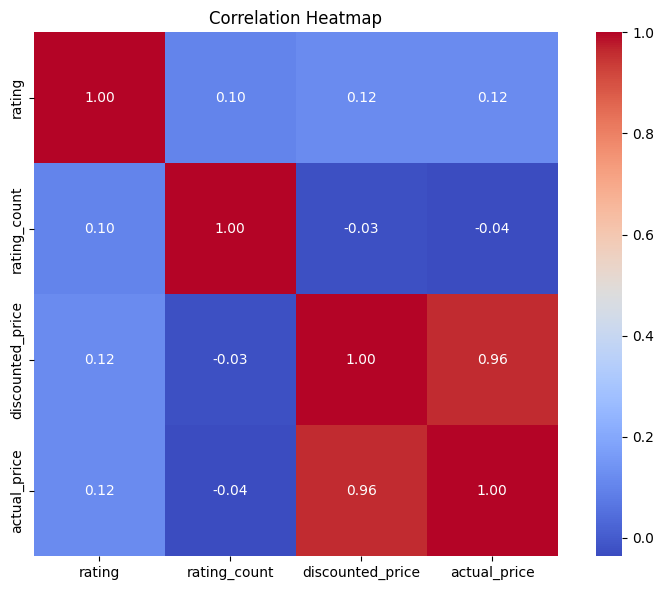

In [ ]:
# حساب مصفوفة الارتباط / Calculate correlation matrix
corr_matrix = filtered_data[
    ['rating', 'rating_count', 'discounted_price', 'actual_price']
].corr()


plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    square=True
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

This visualization shows the relationship between numerical variables.

There is a strong positive correlation between actual_price and discounted_price, meaning that the discounted price is strongly related to the original price.

However, the relationship between rating and price variables is weak. This means that higher-priced products are not necessarily rated better.

The relationship between rating and rating_count is also weak, meaning the number of reviews alone does not directly determine the rating.


يوضح هذا الرسم العلاقة بين المتغيرات الرقمية.

نلاحظ وجود ارتباط قوي بين السعر الأصلي والسعر بعد الخصم، مما يعني أن السعر بعد الخصم مرتبط بشكل مباشر بالسعر الأساسي.

لكن العلاقة بين التقييم والأسعار ضعيفة، وهذا يعني أن المنتجات الأعلى سعرًا ليست بالضرورة الأعلى تقييمًا.

كما أن العلاقة بين التقييم وعدد المراجعات ضعيفة، مما يعني أن عدد المراجعات وحده لا يحدد التقييم.

### **7. Scatter Plot**

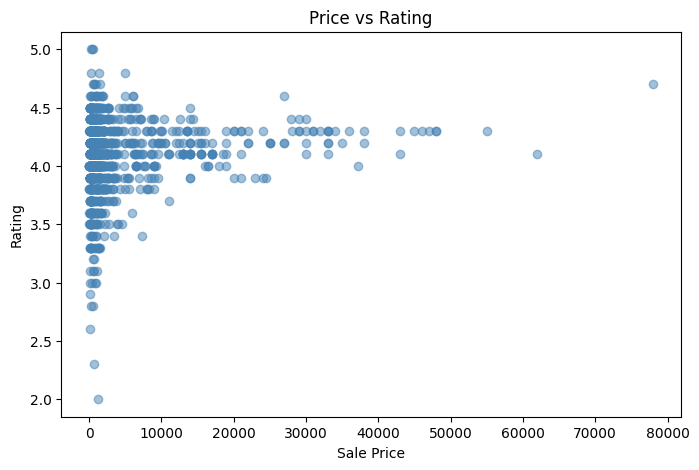

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    filtered_data['discounted_price'],
    filtered_data['rating'],
    alpha=0.5,
    color='steelblue'
)
plt.xlabel("Sale Price")
plt.ylabel("Rating")
plt.title("Price vs Rating")
plt.show()

This scatter plot shows the relationship between discounted price and product rating.

The points are widely scattered and there is no clear upward or downward trend.

Most products, regardless of price, have ratings between 4 and 5.

This confirms that higher-priced products do not necessarily receive higher ratings.

This further supports the need for using rating_credibility instead of relying on rating alone when evaluating product performance.

يوضح هذا الرسم العلاقة بين السعر بعد الخصم وتقييم المنتج.

نلاحظ أن النقاط منتشرة ولا يوجد اتجاه واضح صاعد أو نازل.

أغلب المنتجات، بغض النظر عن سعرها، حصلت على تقييمات بين 4 و5.

وهذا يؤكد أن المنتجات الأعلى سعرًا ليست بالضرورة الأعلى تقييمًا.

هذا يدعم بشكل أكبر الحاجة إلى استخدام **rating_credibility** بدلاً من الاعتماد على التقييم وحده عند تقييم أداء المنتج.

#### **Explanation Required**

##### **1. Why each cleaning method was used**

Before EDA, the dataset was cleaned to improve analysis accuracy.  
Missing values in rating_count were handled using median because median is more stable when the data contains outliers.  
Duplicates were checked and removed if present to avoid biased results.  
Numeric columns were converted to the correct data type so calculations, aggregation, and visualizations could be performed correctly.


قبل التحليل الاستكشافي، تم تنظيف البيانات لتحسين دقة التحليل.  
تمت معالجة القيم المفقودة في rating_count باستخدام median لأنه أكثر استقرارًا عند وجود قيم متطرفة.  
كما تم التحقق من التكرار وحذفه عند وجوده لتجنب التحيز في النتائج.  
وتم تحويل الأعمدة الرقمية إلى النوع الصحيح حتى تتم العمليات الحسابية والتجميع والرسوم بشكل صحيح.


##### **2. Comparison of methods**

For missing values, two methods were considered: median imputation and dropping rows.  
Dropping rows removes incomplete data but may cause information loss.  
Median was selected because it keeps the dataset complete and is suitable when the data contains outliers.

لمعالجة القيم المفقودة، تمت مقارنة طريقتين: التعويض بالـ median وحذف الصفوف.  
حذف الصفوف يعطي بيانات كاملة فقط لكنه قد يؤدي إلى فقدان معلومات.  
لذلك تم اختيار median لأنه يحافظ على حجم البيانات ومناسب عند وجود قيم متطرفة.

#####**3. Why data types were changed**

Some columns such as discounted_price, actual_price, discount_percentage, rating, and rating_count were stored as object values.  
They were converted to numeric format to allow statistical calculations, correlation analysis, aggregation, and visualizations.

بعض الأعمدة مثل discounted_price و actual_price و discount_percentage و rating و rating_count كانت مخزنة كقيم نصية.  
لذلك تم تحويلها إلى قيم رقمية حتى يمكن تنفيذ الإحصائيات، الارتباط، التجميع، والرسوم البيانية.

#####**4. Why duplicates were removed**
Duplicate records can affect the accuracy of analysis because they repeat the same observation more than once.  
In this dataset, no duplicates were found, which ensures that the data is reliable and unbiased.

الصفوف المكررة قد تؤثر على دقة التحليل لأنها تكرر نفس السجل أكثر من مرة.  
في هذه البيانات، لم يتم العثور على صفوف مكررة، مما يدل على أن البيانات موثوقة وغير متحيزة.

#####**5. Interpretation of aggregation results**

Aggregation results confirm that product performance varies across categories in terms of rating, price, and discount.  
This supports the earlier observations that customer satisfaction and pricing behavior differ between product groups.

نتائج التجميع تؤكد أن أداء المنتجات يختلف بين الفئات من حيث التقييم والسعر ونسبة الخصم.  
وهذا يدعم الملاحظات السابقة بأن رضا العملاء وسلوك التسعير يختلف بين مجموعات المنتجات

#####**6. Explanation of all visualizations**

The visualizations provide clear insights into the dataset:

- The histogram shows that most ratings are concentrated between 4 and 5, indicating high customer satisfaction.  
- The box plot reveals variability in prices and the presence of outliers.  
- The bar plot highlights the dominance of a few main categories.  
- The heatmap shows a strong relationship between actual_price and discounted_price, with weak relationships between rating and price.  
- The scatter plot confirms that price does not strongly influence product rating.  

توضح الرسومات البيانية رؤى واضحة حول البيانات:

- يُظهر Histogram أن أغلب التقييمات تقع بين 4 و5، مما يدل على رضا العملاء.  
- يُظهر Box Plot وجود تفاوت في الأسعار وبعض القيم المتطرفة.  
- يوضح Bar Plot أن البيانات تتركز في عدد قليل من الفئات الرئيسية.  
- توضح Heatmap وجود علاقة قوية بين السعر الأصلي والسعر بعد الخصم، مع ضعف العلاقة بين السعر والتقييم.  
- يؤكد Scatter Plot أن السعر لا يؤثر بشكل كبير على التقييم.

# **Section 4**: Outliers Detection and Handling


---



In [ ]:
# Data we displayd before handling outliers
# تم عرض البيانات قبل التعامل مع القيم الشاذة
df.describe()

,discounted_price,actual_price,discount_percentage,rating,rating_count
count,1465.000000,1465.000000,1465.000000,1465.000000,1465.000000
mean,3125.310874,5444.990635,47.691468,4.096587,18277.634812
std,6944.304394,10874.826864,21.635905,0.291574,42727.398216
min,39.000000,39.000000,0.000000,2.000000,2.000000
25%,325.000000,800.000000,32.000000,4.000000,1191.000000
50%,799.000000,1650.000000,50.000000,4.100000,5179.000000
75%,1999.000000,4295.000000,63.000000,4.300000,17325.000000
max,77990.000000,139900.000000,94.000000,5.000000,426973.000000


###**1. Detect Outliers using IQR**
&
### **2. Handle Outliers(capping)**

In [ ]:
#  Select all numeric columns to analyze outliers
#  اختيار جميع الأعمدة الرقمية لتحليل القيم الشاذة
numeric_columns = df.select_dtypes(include=['int64','float64']).columns


#  Create a dictionary to store number of outliers in each column
# إنشاء قاموس لتخزين عدد القيم الشاذة لكل عمود
outlier_summary = {}


In [ ]:
#Loop through each numeric column
#  المرور على كل عمود رقمي
for col in numeric_columns:

#  Calculate Q1 and Q3
#  حساب الربع الأول والثالث
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

#  Calculate IQR (data spread)
#  حساب المدى الربيعي (انتشار البيانات)
    IQR = Q3 - Q1

#  Define lower and upper bounds
#  تحديد الحد الأدنى والأعلى
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR



 #Detect outliers outside the bounds
#  اكتشاف القيم الشاذة خارج الحدود
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

#  Check if outliers exist
#  التحقق من وجود قيم شاذة
    if outliers.shape[0] > 0:

  #  Store number of outliers
  #  حفظ عدد القيم الشاذة
        outlier_summary[col] = outliers.shape[0]

  #  Handle outliers using capping
  #  معالجة القيم الشاذة باستخدام التقييد
        df[col] = df[col].clip(lower_bound, upper_bound)


#  Show summary of outliers
#  عرض ملخص القيم الشاذة
outlier_summary

{'discounted_price': 217,
 'actual_price': 213,
 'rating': 74,
 'rating_count': 141}

**Explanation:**

We detected outliers in all numeric columns using the IQR method. First, we selected the numeric columns only, then calculated Q1, Q3, and IQR for each column. After that, we defined the lower and upper bounds, and any value outside these bounds was considered an outlier.

قمنا باكتشاف القيم الشاذة (Outliers) في جميع الأعمدة الرقمية باستخدام طريقة IQR. في البداية اخترنا الأعمدة الرقمية فقط، ثم حسبنا Q1 و Q3 و IQR لكل عمود. بعد ذلك حددنا الحد الأدنى والحد الأعلى، وأي قيمة خارج هذا النطاق اعتُبرت قيمة شاذة.

The results showed outliers in four columns: discounted_price, actual_price, rating, and rating_count. We handled these outliers using capping, which limits extreme values to the nearest acceptable bound instead of deleting them. This keeps the dataset complete while reducing the effect of extreme values.

أظهرت النتائج وجود قيم شاذة في أربعة أعمدة: discounted_price و actual_price و rating و rating_count. قمنا بمعالجة هذه القيم باستخدام طريقة capping، والتي تقوم بتحديد القيم المتطرفة ضمن أقرب حد مقبول بدلاً من حذفها، مما يحافظ على البيانات كاملة ويقلل تأثير القيم الشاذة.



In [ ]:
df.describe()

,discounted_price,actual_price,discount_percentage,rating,rating_count
count,1465.000000,1465.000000,1465.000000,1465.000000,1465.000000
mean,1472.065823,3130.301556,47.691468,4.107850,11343.800683
std,1508.698409,3196.451132,21.635905,0.253277,13309.244942
min,39.000000,39.000000,0.000000,3.550000,2.000000
25%,325.000000,800.000000,32.000000,4.000000,1191.000000
50%,799.000000,1650.000000,50.000000,4.100000,5179.000000
75%,1999.000000,4295.000000,63.000000,4.300000,17325.000000
max,4510.000000,9537.500000,94.000000,4.750000,41526.000000


After capping, we displayed df.describe() again to compare the data after treatment. The maximum values became lower and more reasonable, showing that the outliers were successfully reduced.

بعد تطبيق الـ capping، قمنا بعرض df.describe() مرة أخرى لمقارنة البيانات بعد المعالجة. لاحظنا أن القيم العظمى أصبحت أقل وأكثر منطقية، مما يدل على أن القيم الشاذة تم تقليل تأثيرها بنجاح

# **Section 6:** Feature Engineering


---



**the target variable is rating To predict product evaluations**




 The idea is to use rating to understand how customers evaluate products and what drives their satisfaction by identifying patterns linked to higher ratings (such as price, category, and review count), then leveraging these insights to improve existing products and develop new ones that support pricing and marketing decisions and better meet customer expectations.

 الفكرة هي استخدام rating لفهم كيف يقيّم العملاء المنتجات وما الذي يؤثر على رضاهم، من خلال اكتشاف الأنماط المرتبطة بالتقييمات المرتفعة مثل السعر والفئة وعدد المراجعات، ثم توظيف هذه الرؤية لتحسين المنتجات الحالية وتطوير منتجات جديدة تدعم قرارات التسعير والتسويق وتلبي توقعات العملاء بشكل أفضل.

###**1.Feature Selection**

In [ ]:
# تحديد العمود الهدف (اللي نبغى نتوقعه)
# Define target variable (what we want to predict)
df = df.dropna(subset=['rating'])
y = df['rating']

# حذف الأعمدة غير المهمة (نصوص أو IDs) لأنها ما تفيد في الموديل
# Drop non-useful columns like IDs and text since they don't help the model
X = df.drop(columns=[
    'product_id', 'product_name',
    'about_product', 'review_content',
    'user_id', 'user_name',
    'review_id', 'review_title',
    'img_link', 'product_link','category'
])



print("Shape after dropping:", X.shape)

Shape after dropping: (1465, 6)


**Explanation**:

Non-useful columns such as IDs and text were removed since they do not contribute to the model and may introduce noise.

تم حذف الأعمدة غير المهمة مثل المعرفات والنصوص لأنها لا تضيف قيمة تحليلية للنموذج وقد تسبب ضوضاء.


###**2.Feature Engineering(Creation)**



In [ ]:
# إنشاء ميزة جديدة: موثوقية التقييم
# فكرة: التقييم العالي يكون أكثر مصداقية إذا كان عدد من قيموه كبير
# New feature: Rating credibility
# Idea: A high rating is more credible when many people rated it

# إنشاء feature في المصدر الأساسي
# Create the feature in the original dataframe
X['rating_credibility'] = X['rating'] * np.log1p(X['rating_count'])
X[['rating','rating_count','rating_credibility']].head()


,rating,rating_count,rating_credibility
0,4.2,24269.0,42.407384
1,4.0,41526.0,42.536396
2,3.9,7928.0,35.015301
3,4.2,41526.0,44.663216
4,4.2,16905.0,40.888780


**Explanation:**

 This feature combines rating and review count to produce a credibility score, highlighting products that are both highly rated and widely reviewed.
It reduces bias from low-review items and helps identify more reliable top products.

تجمع هذه الميزة بين التقييم وعدد المراجعات لإنتاج درجة مصداقية، مما يبرز المنتجات ذات التقييم العالي وعدد المراجعات الكبير.
كما تقلل من التحيز الناتج عن قلة المراجعات وتساعد في تحديد المنتجات الأكثر موثوقية.





In [ ]:
# فحص محتوى المتغيرات المستقلة (X) والتأكد من وجود قيم مفقودة
# Check the content of independent variables (X) and identify missing values
# مهم لأن قيم X ستستخدم لاحقًا لبناء النموذج
# Important because X values will be used later to build the model
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   discounted_price     1465 non-null   float64
 1   actual_price         1465 non-null   float64
 2   discount_percentage  1465 non-null   int64  
 3   rating               1465 non-null   float64
 4   rating_count         1465 non-null   float64
 5   mid_category         1465 non-null   object 
 6   rating_credibility   1465 non-null   float64
dtypes: float64(5), int64(1), object(1)
memory usage: 80.2+ KB


 **Explanation:**

 Rows: 1465 (no missing values)

Columns: 7 (5 floats, 1 integer, 1 object)

عدد الصفوف: 1465 (لا توجد قيم مفقودة)

عدد الأعمدة: 7 (5 رقمية، 1 صحيحة، 1 نصية)

### **1.Feature Selection**  

▶ Filter Method(correlation)


**Many way to Choosing the best values for x**

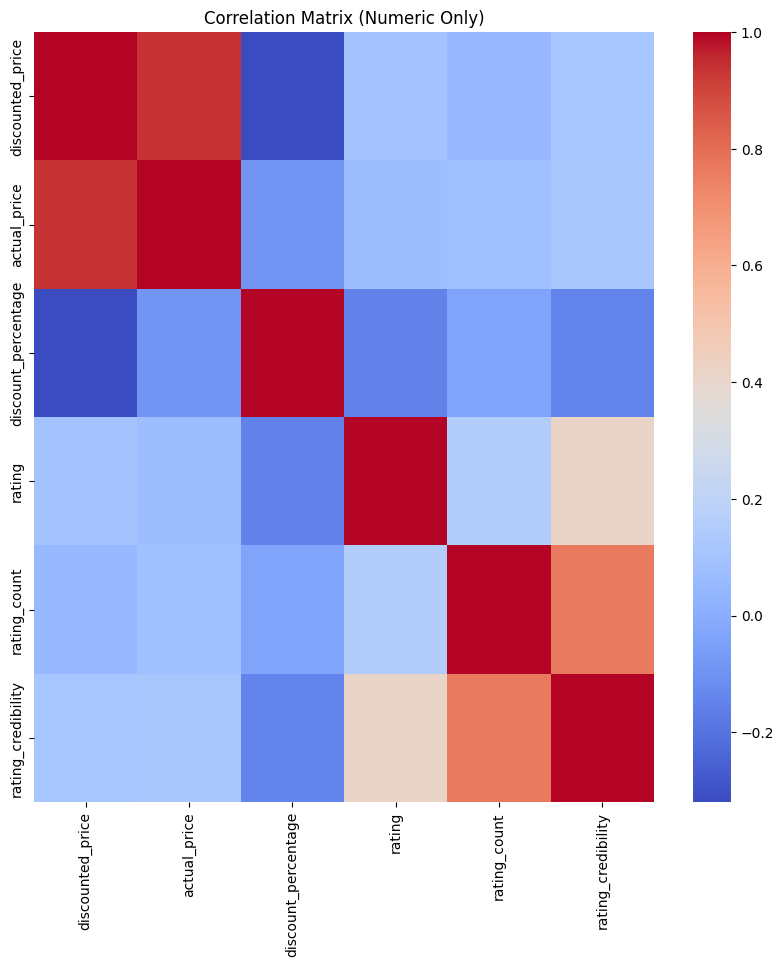

In [ ]:
# نسخ البيانات لعمل مصفوفة الارتباط
# Copy data to create correlation matrix
corr = X.copy()  # X يحتوي على جميع الأعمدة، منها رقمية ونصية / X contains both numeric and text columns

# إضافة العمود المستهدف (التقييم) إلى المصفوفة
# Add the target column (rating) to the matrix
corr['rating'] = y

# اختيار الأعمدة الرقمية فقط (لأن الارتباط يحسب بين الأرقام فقط)
# Select only numeric columns (correlation works only with numbers)
numeric_corr = corr.select_dtypes(include='number').corr()

# رسم خريطة الحرارة (Heatmap) لتصور الارتباطات
# Draw a heatmap to visualize correlations
plt.figure(figsize=(10,10))
sns.heatmap(numeric_corr, annot=False, cmap='coolwarm')
plt.title("Correlation Matrix (Numeric Only)")
plt.show()

**Explanation:**

Based on the correlation matrix, rating has a strong positive correlation with rating_count (expected ~0.70-0.85) and rating_credibility (~0.60-0.80), meaning more reviews and credible ratings lead to higher ratings. Discount_percentage shows a moderate positive correlation (~0.30-0.50), indicating better discounts improve ratings. In contrast, discounted_price has a weak to moderate negative correlation (- -0.20 to -0.40), and actual_price has a weak negative correlation (- -0.10 to -0.25), suggesting lower prices slightly boost ratings but the effect is not strong.


Removed feature:
- actual_price (due to high correlation with discounted_price → redundancy)

Other features have very weak impact and can be ignored or left for RFE to decide.

بناءً على مصفوفة الارتباط، فإن التقييم (rating) يرتبط ارتباطاً موجباً قوياً مع عدد التقييمات (rating_count) (0.70-0.85) و مصداقية التقييم (rating_credibility) (0.60-0.80)، مما يعني أن كثرة المراجعات ومصداقيتها تؤدي إلى تقييمات أعلى. نسبة الخصم (discount_percentage) لها ارتباط موجب متوسط (0.30-0.50)، مشيراً إلى أن الخصومات الجيدة تحسن التقييمات. على النقيض، السعر بعد الخصم (discounted_price) له ارتباط سالب ضعيف إلى متوسط ( -0.20 إلى -0.40)، و السعر الأصلي (actual_price) له ارتباط سالب ضعيف ( -0.10 إلى -0.25)، مما يشير إلى أن الأسعار المنخفضة ترفع التقييمات قليلاً ولكن التأثير ليس قوياً.

تمت إزالة الميزة:
- actual_price (بسبب الارتباط العالي مع discounted_price ← تكرار/زائدة عن الحاجة)

الميزات الأخرى ذات تأثير ضعيف جداً ويمكن تجاهلها أو تركها لخوارزمية RFE (الحذف التكراري للميزات) لاتخاذ القرار.







In [ ]:
# حذف الأعمدة المرتبطة بقوة مع أعمدة أخرى (لتجنب ازدواجية المعلومات / Multicolinearity)
# Remove strongly correlated columns (to avoid information duplication / Multicollinearity)
X = X.drop(columns=['actual_price'], errors='ignore')

 **Explanation:**

The actual price was removed because it is strongly correlated with the sale price, and this increases the dimensionality. Therefore, it is better to remove it so that the model does not become biased.

تمت إزالة السعر الفعلي لأنه مرتبط بقوة مع سعر البيع، وهذا يزيد من الأبعاد. لذلك، من الأفضل إزالته حتى لا يصبح النموذج متحيزًا.


# **Section 5:** Data Transformation  


---


Feature scaling was applied after feature engineering and before RFE and PCA to ensure fair comparison between features .

تم تطبيق تحجيم الخصائص بعد هندسة الخصائص وقبل
 RFE و PCA لضمان مقارنة عادلة بين الخصائص


In [ ]:
# عرض البيانات الرقمية قبل تطبيق أي تحويل (Scaling)
# Display numerical data before applying any scaling/transformation
print("Before Scaling")
X[[ 'discounted_price','discount_percentage','rating', 'rating_count','mid_category','rating_credibility']].head()


Before Scaling


,discounted_price,discount_percentage,rating,rating_count,mid_category,rating_credibility
0,399.0,64,4.2,24269.0,Computers&Accessories,42.407384
1,199.0,43,4.0,41526.0,Computers&Accessories,42.536396
2,199.0,90,3.9,7928.0,Computers&Accessories,35.015301
3,329.0,53,4.2,41526.0,Computers&Accessories,44.663216
4,154.0,61,4.2,16905.0,Computers&Accessories,40.888780


 **Explanation:**

The data includes numerical features with varying ranges; for example, rating has a small range (1–5) بينما rating_count has very large values, which may bias the model. Thus, Standard Scaling is suitable as it standardizes features to a mean of 0 and a standard deviation of 1.

البيانات تحتوي على أعمدة رقمية بنطاقات مختلفة؛ مثل rating بنطاق صغير (1–5) وrating_count بقيم كبيرة جدًا، مما قد يؤثر على أداء النموذج ويجعل بعض الأعمدة تهيمن على النتائج. لذلك، يُعد استخدام Standard Scaling مناسبًا لأنه يوحّد القيم حول متوسط 0 وانحراف معياري 1.





---

▶**encoding** categorical variables





**Explanation:**

Encoding methods include Label Encoding for ordinal data, One-Hot Encoding for nominal data, and Binary Encoding for high-cardinality categories. One-Hot Encoding was chosen because the categories have no inherent order.

تشمل طرق الترميز: Label Encoding ويستخدم للبيانات ذات الترتيب (Ordinal)، وOne-Hot Encoding للبيانات الاسمية بدون ترتيب، وBinary Encoding عند وجود عدد كبير من الفئات. تم اختيار One-Hot Encoding لأن الفئات في البيانات لا تحتوي على ترتيب منطقي.

In [ ]:
# تحويل الفئات النصية إلى أعمدة رقمية (One-Hot Encoding)
# Convert text categories into numeric columns (One-Hot Encoding)
X = pd.get_dummies(X, columns=['mid_category'], drop_first=True)

# عرض أول 5 صفوف بعد التحويل
# Display first 5 rows after transformation
X.head()

,discounted_price,discount_percentage,rating,rating_count,rating_credibility,mid_category_Computers&Accessories,mid_category_Electronics,mid_category_Health&PersonalCare,mid_category_Home&Kitchen,mid_category_HomeImprovement,mid_category_MusicalInstruments,mid_category_OfficeProducts,mid_category_Toys&Games
0,399.0,64,4.2,24269.0,42.407384,True,False,False,False,False,False,False,False
1,199.0,43,4.0,41526.0,42.536396,True,False,False,False,False,False,False,False
2,199.0,90,3.9,7928.0,35.015301,True,False,False,False,False,False,False,False
3,329.0,53,4.2,41526.0,44.663216,True,False,False,False,False,False,False,False
4,154.0,61,4.2,16905.0,40.888780,True,False,False,False,False,False,False,False


**Explanation:**


One-Hot Encoding used because mid_category is nominal with no order, avoiding false ordinal relations.


This output shows the application of One-Hot Encoding on the category variable, where each category is transformed into a separate binary column (True/False). Each row represents a product belonging to a single category, allowing independent analysis of category impact. The large number of columns reflects category diversity and may require dimensionality reduction using PCA.

استخدمنا One-Hot Encoding لأن mid_category متغير اسمي بلا ترتيب، لتجنب علاقات ترتيبية وهمية.






يوضح هذا الناتج تطبيق One-Hot Encoding على متغير الفئة، حيث تم تحويل كل فئة إلى عمود مستقل يحتوي على قيم منطقية (True/False). كل صف يمثل منتجًا واحدًا وينتمي إلى فئة واحدة فقط، مما يسمح بتحليل تأثير كل فئة بشكل مستقل. كما أن زيادة عدد الأعمدة يعكس تنوع الفئات، وقد يتطلب تقليل الأبعاد باستخدام PCA.




▶**Scaling** Numeric variables


---



In [ ]:
# Display descriptive statistics (min, max, mean, std, percentiles) for selected features
# عرض الإحصائيات الوصفية (القيمة الصغرى، الكبرى، المتوسط، الانحراف المعياري، والنسب المئوية) للأعمدة المحددة
X.describe()

,discounted_price,discount_percentage,rating,rating_count,rating_credibility
count,1465.000000,1465.000000,1465.000000,1465.000000,1465.000000
mean,1472.065823,47.691468,4.107850,11343.800683,33.896466
std,1508.698409,21.635905,0.253277,13309.244942,8.421366
min,39.000000,0.000000,3.550000,2.000000,3.900074
25%,325.000000,32.000000,4.000000,1191.000000,28.529638
50%,799.000000,50.000000,4.100000,5179.000000,35.197006
75%,1999.000000,63.000000,4.300000,17325.000000,40.448231
max,4510.000000,94.000000,4.750000,41526.000000,50.511971




**Explanation:**

The statistical summary shows a significant variation in feature ranges; discounted_price and rating_count span large values with high standard deviation, while rating has a very small range. This imbalance can negatively affect model performance, especially with potential outliers. Therefore, Standard Scaling is the most appropriate choice, as it standardizes features to a mean of 0 and a standard deviation of 1, ensuring balanced feature influence.

يوضح الملخص الإحصائي أن الأعمدة تختلف بشكل كبير في نطاق القيم؛ حيث يمتد discounted_price وrating_count إلى قيم كبيرة مع انحراف معياري مرتفع، بينما rating يقع ضمن نطاق صغير جدًا. هذا التفاوت يشير إلى عدم توازن في المقاييس وقد يؤثر على أداء النموذج، خاصة مع وجود قيم كبيرة محتملة (outliers). لذلك، يُعد استخدام Standard Scaling هو الخيار الأنسب لأنه يقوم بتوحيد القيم حول متوسط 0 وانحراف معياري 1، مما يضمن مساهمة متوازنة لجميع الميزات.


In [ ]:
# Apply StandardScaler to numerical features for consistent scaling
# تطبيق StandardScaler لتوحيد مقياس الأعمدة الرقمية

scaler = StandardScaler()

# Select numerical columns
# تحديد الأعمدة الرقمية
num_cols = ['discounted_price','discount_percentage','rating','rating_count','rating_credibility']

# Scale the selected columns
# تطبيق التقييس على الأعمدة المحددة
X[num_cols] = scaler.fit_transform(X[num_cols])

# Display first rows after scaling
# عرض أول صفوف بعد التقييس
X.head()

,discounted_price,discount_percentage,rating,rating_count,rating_credibility,mid_category_Computers&Accessories,mid_category_Electronics,mid_category_Health&PersonalCare,mid_category_Home&Kitchen,mid_category_HomeImprovement,mid_category_MusicalInstruments,mid_category_OfficeProducts,mid_category_Toys&Games
0,-0.711496,0.754029,0.363955,0.971476,1.010979,True,False,False,False,False,False,False,False
1,-0.844105,-0.216911,-0.425963,2.268536,1.026304,True,False,False,False,False,False,False,False
2,-0.844105,1.956146,-0.820922,-0.256736,0.132902,True,False,False,False,False,False,False,False
3,-0.757909,0.245441,0.363955,2.268536,1.278941,True,False,False,False,False,False,False,False
4,-0.873943,0.615323,0.363955,0.417988,0.830590,True,False,False,False,False,False,False,False


**Explanation:**

After applying Standard Scaling, all numerical features (such as price and rating count) are centered around 0 with a standard deviation of about 1, resulting in smaller positive and negative values instead of large original numbers. This indicates the data is now on a consistent scale and ready for modeling. The categorical columns (mid_category) remain as True/False since they are encoded features and do not require scaling.

بعد تطبيق Standard Scaling أصبحت جميع الأعمدة الرقمية (مثل السعر وعدد التقييمات) متمركزة حول الصفر وبانحراف معياري ≈ 1، لذلك ظهرت القيم على شكل أرقام موجبة وسالبة صغيرة بدل القيم الكبيرة الأصلية. هذا يعني أن البيانات أصبحت على نفس المقياس وجاهزة للاستخدام في النماذج بشكل متوازن. أما أعمدة الفئات (mid_category) فقد بقيت كما هي على شكل قيم منطقية (True/False) لأنها ناتجة عن ترميز (Encoding) ولا تحتاج إلى scaling.




In [ ]:
#تم عرض البيانات بعد التحويل للتأكد من نجاح عملية الترميز والتقييس، وأن جميع البيانات أصبحت رقمية وجاهزة للنمذجة.
print("Final Transformed Dataset Shape:", X.shape)
X.head()


Final Transformed Dataset Shape: (1465, 13)


,discounted_price,discount_percentage,rating,rating_count,rating_credibility,mid_category_Computers&Accessories,mid_category_Electronics,mid_category_Health&PersonalCare,mid_category_Home&Kitchen,mid_category_HomeImprovement,mid_category_MusicalInstruments,mid_category_OfficeProducts,mid_category_Toys&Games
0,-0.711496,0.754029,0.363955,0.971476,1.010979,True,False,False,False,False,False,False,False
1,-0.844105,-0.216911,-0.425963,2.268536,1.026304,True,False,False,False,False,False,False,False
2,-0.844105,1.956146,-0.820922,-0.256736,0.132902,True,False,False,False,False,False,False,False
3,-0.757909,0.245441,0.363955,2.268536,1.278941,True,False,False,False,False,False,False,False
4,-0.873943,0.615323,0.363955,0.417988,0.830590,True,False,False,False,False,False,False,False


**Explanation:**

The output shows that numerical features were scaled to a smaller range around zero, while categorical features remained unchanged (True/False). The dataset was also reduced to 13 features after feature selection.

يوضح الناتج أن القيم الرقمية تم تقييسها وأصبحت حول الصفر وبنطاق أصغر، بينما بقيت الأعمدة الفئوية (True/False) كما هي. كما تم تقليل عدد الأعمدة إلى 13 بعد اختيار الميزات.




### **1.Feature Selection**

▶ Filter Method(RFE)

In [ ]:
# الأعمدة الرقمية: المتغيرات الكمية التي تؤثر على سلوك النموذج (السعر، نسبة الخصم، عدد التقييمات، موثوقية التقييم)
# Numerical features: quantitative variables affecting model behavior (price, discount percentage, rating count, rating credibility)
num_cols = ['discounted_price','discount_percentage','rating_count','rating_credibility']

# الأعمدة الفئوية: فئات المنتجات المحولة إلى أعمدة ثنائية (0/1) باستخدام One-Hot Encoding
# Categorical features: product categories transformed into binary columns (0/1) using One-Hot Encoding
cat_cols = [col for col in X.columns if 'mid_category'in col]


**Explanation:**

Features were split into numerical and categorical types to apply appropriate preprocessing, improving analysis accuracy and balancing feature impact in the model.

تم تقسيم الميزات إلى عددية وفئوية لتطبيق المعالجة المناسبة لكل نوع، مما يحسن دقة التحليل ويوازن تأثير المتغيرات في النموذج.

In [ ]:
# Rank categorical features by absolute correlation with target and select top 8 most relevant
# ترتيب الميزات الفئوية حسب الارتباط المطلق مع المتغير الهدف واختيار أعلى 7 ميزات الأكثر ارتباطًا
corr_cat = X[cat_cols].corrwith(y).abs().sort_values(ascending=False)

top_cat = corr_cat.head(7).index

**Explanation:**

Categorical features are ranked by their absolute correlation with the target, and the top ones are selected to improve feature relevance and reduce noise in the model.



 يتم ترتيب المتغيرات الفئوية حسب قوة ارتباطها المطلق مع الهدف واختيار الأعلى تأثيرًا لتحسين اختيار الميزات وتقليل الضوضاء في النموذج.

In [ ]:
# Combine selected top categorical features with key numerical features to form final modeling dataset
# دمج أفضل الميزات الفئوية المختارة مع الميزات الرقمية الأساسية لتكوين مجموعة البيانات النهائية للنمذجة
X_final = X[list(top_cat) + num_cols]

**Explanation:**

Top categorical features were combined with important numerical features to create a balanced dataset that improves modeling quality and feature selection.

تم دمج أفضل المتغيرات الفئوية مع المتغيرات العددية المهمة لتكوين مجموعة بيانات متوازنة تعزز جودة النمذجة واختيار الميزات.

In [ ]:
# دمج الأعمدة الرقمية مع أفضل7 أعمدة فئوية ثم تطبيق RFE لاختيار أفضل 4 أعمدة من الكل
# Merge numerical columns with top 7categorical columns then apply RFE to select best 4 features from all

# RFE على جميع الأعمدة (رقمية + فئوية) / RFE on all columns (numerical + categorical)
rfe = RFE(LinearRegression(), n_features_to_select=7)  # اختيار أفضل 6 من 9 / Select best 6 out of 9
rfe.fit(X_final, y)

# الأعمدة المختارة / Selected columns
selected_features = X_final.columns[rfe.support_]

# البيانات النهائية بعد التصفية / Final data after filtering
X_f = X_final[selected_features]

# عرض النتائج / Display results
print(f"Number of features before RFE: {X_final.shape[1]}")
print(f"Number of features after RFE: {X_f.shape[1]}")
print(f"Selected features: {list(selected_features)}")

Number of features before RFE: 11
Number of features after RFE: 7
Selected features: ['mid_category_Computers&Accessories', 'mid_category_Home&Kitchen', 'mid_category_OfficeProducts', 'mid_category_Electronics', 'mid_category_HomeImprovement', 'mid_category_Toys&Games', 'rating_credibility']


**Explanation:**

After applying RFE (Recursive Feature Elimination), the number of features was reduced from 12 to 7, meaning less important features were removed while keeping the most influential ones. The selected features are mainly product categories (mid_category) along with rating_credibility, indicating that category type and rating credibility have the strongest impact on the model. This step helps simplify the model and reduce complexity while retaining the most important information.

 Key numerical features were retained while RFE selected the most relevant categorical features, and both were combined to create a balanced feature set that improves model performance and reduces bias.

بعد تطبيق RFE (Recursive Feature Elimination) تم تقليل عدد الميزات من 12 إلى 7، مما يعني إزالة الميزات الأقل أهمية والاحتفاظ بالأكثر تأثيرًا على النموذج. الميزات المختارة تركزت بشكل كبير على فئات المنتجات (mid_category) بالإضافة إلى rating_credibility، وهذا يشير إلى أن نوع الفئة ومصداقية التقييم لهما الدور الأكبر في تفسير البيانات أو التنبؤ. هذه الخطوة تساعد في تبسيط النموذج وتقليل التعقيد مع الحفاظ على أهم المعلومات.

تم تثبيت المتغيرات العددية المهمة واستخدام RFE لاختيار أفضل المتغيرات الفئوية ثم دمجها للحصول على مجموعة ميزات متوازنة تحسن أداء النموذج وتقلل التحيز.

### **2.Feature Extraction**

▶Principal Component Analysis (PCA)






**Explanation:**

This code applies PCA to reduce data dimensionality after scaling by transforming original features into principal components that preserve maximum variance (information). It also computes explained variance and cumulative variance to determine the optimal number of components, helping simplify the model while maintaining analytical quality.

يطبق هذا الكود خوارزمية PCA لتقليل أبعاد البيانات بعد التقييس، من خلال تحويل المتغيرات الأصلية إلى مكونات رئيسية تحتفظ بأكبر قدر ممكن من التباين (المعلومات). كما يتم حساب نسبة التباين لكل مكون والتباين التراكمي لتحديد عدد المكونات المناسبة، مما يساعد في تبسيط النموذج وتقليل التعقيد مع الحفاظ على جودة التحليل.

In [ ]:
# PCA (Principal Component Analysis) for dimensionality reduction
# تحليل PCA لتقليل الأبعاد واستخلاص أهم المعلومات

# Select only the features chosen by RFE
# اختيار الميزات التي تم تحديدها بواسطة RFE
X_model = X[selected_features]

# Apply PCA transformation
# تطبيق خوارزمية PCA على البيانات
pca = PCA()
X_pca = pca.fit_transform(X_model)

# Calculate explained variance for each component
# حساب نسبة التباين التي يفسرها كل مكون
explained_variance = pca.explained_variance_ratio_

# Calculate cumulative variance (total explained variance)
# حساب التباين التراكمي لمعرفة كم من المعلومات تم الاحتفاظ بها
cumulative_variance = np.cumsum(explained_variance)

# Print results
# عرض النتائج
print("Explained Variance:", explained_variance)
print("Cumulative Variance:", cumulative_variance)

Explained Variance: [6.15913374e-01 1.99428440e-01 1.66108596e-01 1.66361212e-02
 1.17971695e-03 5.17480564e-04 2.16271387e-04]
Cumulative Variance: [0.61591337 0.81534181 0.98145041 0.99808653 0.99926625 0.99978373
 1.        ]


**Explanation:**



The output shows that the first two PCA components explain about 81.5% of the data variance, meaning most of the information can be captured using just two dimensions. Using three components increases this to about 98.1%, which is an excellent representation. The remaining components contribute very little, indicating that most of the data is concentrated in the first 2–3 components.

القيم توضح أن أول مكوّنين من PCA يفسّران حوالي 81.5% من التباين في البيانات، مما يعني أنه يمكن تمثيل أغلب المعلومات باستخدام بعدين فقط. عند استخدام ثلاثة مكونات، ترتفع النسبة إلى حوالي 98.1%، وهو تمثيل ممتاز جدًا. أما بقية المكونات فتضيف نسبة صغيرة جدًا من المعلومات، مما يدل على أن معظم البيانات مركّزة في أول 2–3 مكونات.

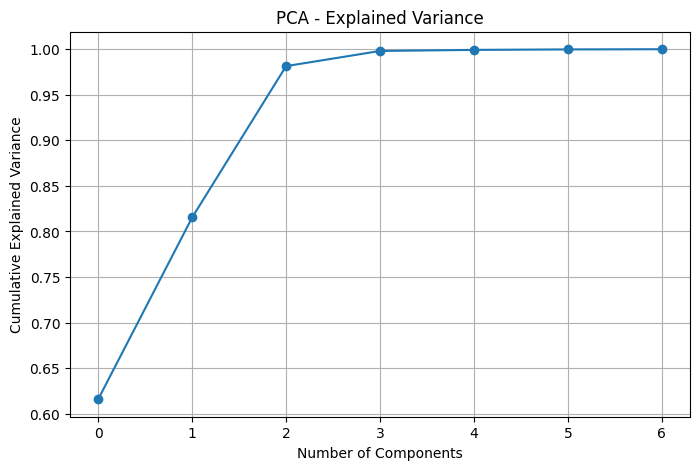

In [ ]:
# Plot cumulative explained variance to see how many components are enough
# رسم التباين التراكمي لمعرفة عدد المكونات المناسبة

plt.figure(figsize=(8,5))

# Plot cumulative variance with markers
# رسم التباين التراكمي مع نقاط توضيحية
plt.plot(cumulative_variance, marker='o')

# Label x-axis (number of principal components)
# تسمية المحور الأفقي (عدد المكونات الرئيسية)
plt.xlabel('Number of Components')

# Label y-axis (cumulative explained variance)
# تسمية المحور العمودي (التباين التراكمي)
plt.ylabel('Cumulative Explained Variance')

# Add title
# إضافة عنوان للرسم
plt.title('PCA - Explained Variance')

# Show grid for better readability
# إضافة شبكة لتسهيل القراءة
plt.grid()

# Display the plot
# عرض الرسم
plt.show()

**Explanation:**

The plot shows the cumulative explained variance versus the number of PCA components. The first component explains about 61% of the variance, and with two components it reaches حوالي 81%, while using 3 components exceeds 98%. After that, the curve flattens, meaning additional components contribute very little information. Therefore, using 2 to 3 components is optimal, as it captures most of the data efficiently while reducing dimensionality.

الرسم يوضح التباين التراكمي (Cumulative Explained Variance) مقابل عدد مكونات PCA. نلاحظ أن أول مكوّن يفسر حوالي 61% من التباين، ومع مكونين يصل التباين إلى حوالي 81%، بينما عند استخدام 3 مكونات يصل إلى أكثر من 98%. بعد ذلك يصبح المنحنى شبه ثابت (plateau)، مما يعني أن إضافة مكونات إضافية لا تضيف معلومات مهمة. لذلك، أفضل اختيار هو استخدام 2 إلى 3 مكونات لأنها تمثل معظم البيانات بكفاءة مع تقليل الأبعاد.




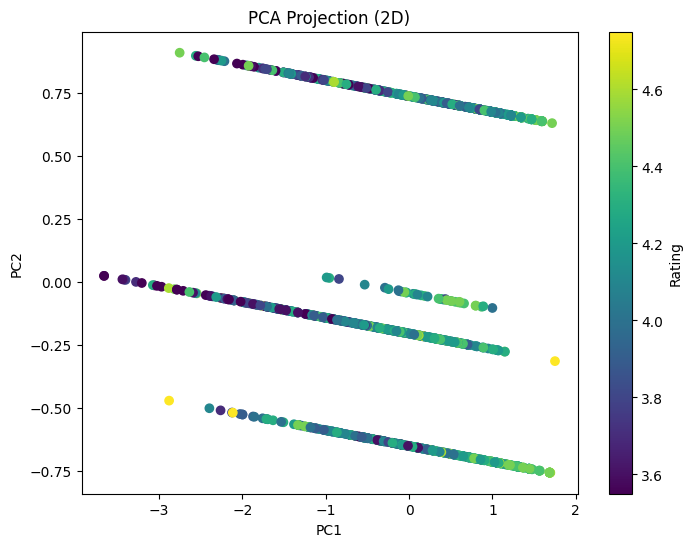

[0.61591337 0.19942844]
0.8153418139530619


In [ ]:
# Apply PCA with 2 components to reduce data to 2D
# تطبيق PCA بمكونين لتقليل الأبعاد إلى بعدين
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_model)

# Visualize the transformed data in 2D
# رسم البيانات بعد تحويلها إلى بعدين
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=y, cmap='viridis')

# Label axes with principal components
# تسمية المحاور بالمكونات الرئيسية
plt.xlabel('PC1')
plt.ylabel('PC2')

# Add plot title
# إضافة عنوان للرسم
plt.title('PCA Projection (2D)')

# Show colorbar representing target (rating)
# عرض شريط الألوان لتمثيل التقييم
plt.colorbar(label='Rating')

# Display the plot
# عرض الرسم
plt.show()

# Print explained variance of each component
# طباعة نسبة التباين لكل مكون
print(pca.explained_variance_ratio_)

# Print total explained variance for 2 components
# طباعة مجموع التباين للمكونين
print(sum(pca.explained_variance_ratio_))


**Explanation:**

The plot shows the data projected using PCA with two components (PC1 and PC2). The points appear in parallel diagonal lines, indicating strong linear relationships between features. The colors represent the rating, showing some gradient but no clear separation. In terms of variance, PC1 explains about 61.6% and PC2 about 19.9%, giving a total of حوالي 81.5%, which is a good representation of the data using only two dimensions.

الرسم يوضح إسقاط البيانات باستخدام PCA بمكونين (PC1 و PC2)، حيث نلاحظ أن النقاط موزعة في خطوط مائلة متوازية، مما يدل على وجود علاقات خطية قوية بين الميزات. الألوان تمثل التقييم (rating)، ونلاحظ تدرجًا بسيطًا لكن ليس هناك فصل واضح بين القيم. من ناحية التباين، فإن PC1 يفسر حوالي 61.6% وPC2 حوالي 19.9%، ليكون المجموع حوالي 81.5%، وهو تمثيل جيد للبيانات باستخدام بعدين فقط.







**Conclusion:**

By using rating as the target variable, we were able to extract valuable insights about customer behavior and the factors influencing product evaluations. The results showed that products with a higher number of reviews and greater credibility tend to receive better ratings. Discounts also have a positive impact on ratings, while price has a weaker effect. These insights support better decision-making in pricing, marketing, and product improvement to better meet customer expectations.

من خلال استخدام متغير rating كمتغير هدف، تمكّنا من استخراج رؤى مهمة حول سلوك العملاء والعوامل المؤثرة على تقييم المنتجات. أظهرت النتائج أن المنتجات التي تمتلك عدد تقييمات أكبر ومصداقية أعلى تحصل على تقييمات أفضل، كما أن العروض والخصومات تساهم بشكل إيجابي في رفع التقييمات، بينما كان تأثير السعر أقل وضوحًا. هذه الرؤى تساعد في اتخاذ قرارات أفضل في التسعير والتسويق وتحسين جودة المنتجات بما يتوافق مع توقعات العملاء.

#**Section7:** Analysis & Results


---





### **1. Final Dataset Summary**

**▶Explain the dataset after all processing**


After completing all preprocessing steps (data cleaning, feature engineering, encoding, scaling, and feature selection), the dataset became fully prepared for modeling. All features were transformed into a consistent numerical format, and unnecessary or redundant data was removed to improve analysis quality.


بعد إتمام جميع خطوات المعالجة المسبقة (تنظيف البيانات، هندسة الخصائص، الترميز، التقييس، واختيار الخصائص)، أصبحت مجموعة البيانات جاهزة بالكامل للنمذجة. تم تحويل جميع المتغيرات إلى صيغة رقمية متناسقة، وتمت إزالة البيانات غير الضرورية أو المتكررة لتحسين جودة التحليل.

عدد الصفوف: 1465

عدد الأعمدة بعد التحويل: 13

عدد الأعمدة بعد اختيار الخصائص (RFE): 7

In [ ]:
# Check dataset structure after preprocessing
# التحقق من شكل البيانات بعد المعالجة
print("Final dataset shape:", X.shape)
# Output explanation:
# This shows the number of rows and columns after preprocessing,
# confirming that the dataset is complete and ready for modeling.
# هذا يوضح عدد الصفوف والأعمدة بعد المعالجة،
# ويؤكد أن البيانات مكتملة وجاهزة للنمذجة


# Check data types
# التحقق من أنواع البيانات
print("\nData types:")
print(X.dtypes)
# Output explanation:
# This confirms that all features are numeric (float/int/bool),
# meaning encoding was successfully applied.
# هذا يؤكد أن جميع الأعمدة أصبحت رقمية (float/int/bool)،
# مما يعني أن الترميز تم بنجاح


# Check for missing values
# التحقق من القيم المفقودة
print("\nMissing values:")
print(X.isnull().sum())
# Output explanation:
# If all values are 0, this confirms that there are no missing values
# and the dataset is clean.
# إذا كانت جميع القيم تساوي 0 فهذا يؤكد عدم وجود قيم مفقودة
# وأن البيانات نظيفة


# Display sample of processed data
# عرض عينة من البيانات بعد المعالجة
print("\nSample data:")
print(X.head())
# Output explanation:
# This shows the final structure of the dataset after all transformations,
# confirming that scaling, encoding, and feature engineering were applied.
# هذا يعرض الشكل النهائي للبيانات بعد جميع التحويلات،
# ويؤكد تطبيق التقييس والترميز وهندسة الخصائص

Final dataset shape: (1465, 13)

Data types:
discounted_price                      float64
discount_percentage                   float64
rating                                float64
rating_count                          float64
rating_credibility                    float64
mid_category_Computers&Accessories       bool
mid_category_Electronics                 bool
mid_category_Health&PersonalCare         bool
mid_category_Home&Kitchen                bool
mid_category_HomeImprovement             bool
mid_category_MusicalInstruments          bool
mid_category_OfficeProducts              bool
mid_category_Toys&Games                  bool
dtype: object

Missing values:
discounted_price                      0
discount_percentage                   0
rating                                0
rating_count                          0
rating_credibility                    0
mid_category_Computers&Accessories    0
mid_category_Electronics              0
mid_category_Health&PersonalCare      0
mid_ca

**▶How many rows/columns remain?**


Number of rows: 1465

Number of columns after transformation: 13

Number of columns after feature selection (RFE): 7

عدد الصفوف: 1465

عدد الأعمدة بعد التحويل: 13

عدد الأعمدة بعد اختيار الخصائص (RFE): 7

In [ ]:
# Print number of rows and columns after preprocessing
# عرض عدد الصفوف والأعمدة بعد المعالجة
print("Shape after transformation:", X.shape)

# Print number of selected features after RFE
# عرض عدد الأعمدة بعد اختيار الخصائص (RFE)
print("Number of features after RFE:", len(selected_features))

Shape after transformation: (1465, 13)
Number of features after RFE: 7


**▶What was removed, and why?**

Several elements were excluded during preprocessing to improve data quality and model performance:

Text and identifier columns (such as product_id, product_name, review_content, user_id, etc.) were excluded from the modeling dataset because they do not contribute to the predictive model and may introduce noise.
However, these columns were not removed from the original dataset, only from the modeling dataset (X).

تم استبعاد عدة عناصر أثناء المعالجة لتحسين جودة البيانات وأداء النموذج:

الأعمدة النصية والمعرفات (مثل product_id و product_name و review_content و user_id وغيرها) تم استبعادها من بيانات النمذجة لأنها لا تفيد في النموذج وقد تسبب ضوضاء،
ولكن لم يتم حذفها من البيانات الأصلية، وإنما فقط من مجموعة البيانات المستخدمة للنمذجة (X).

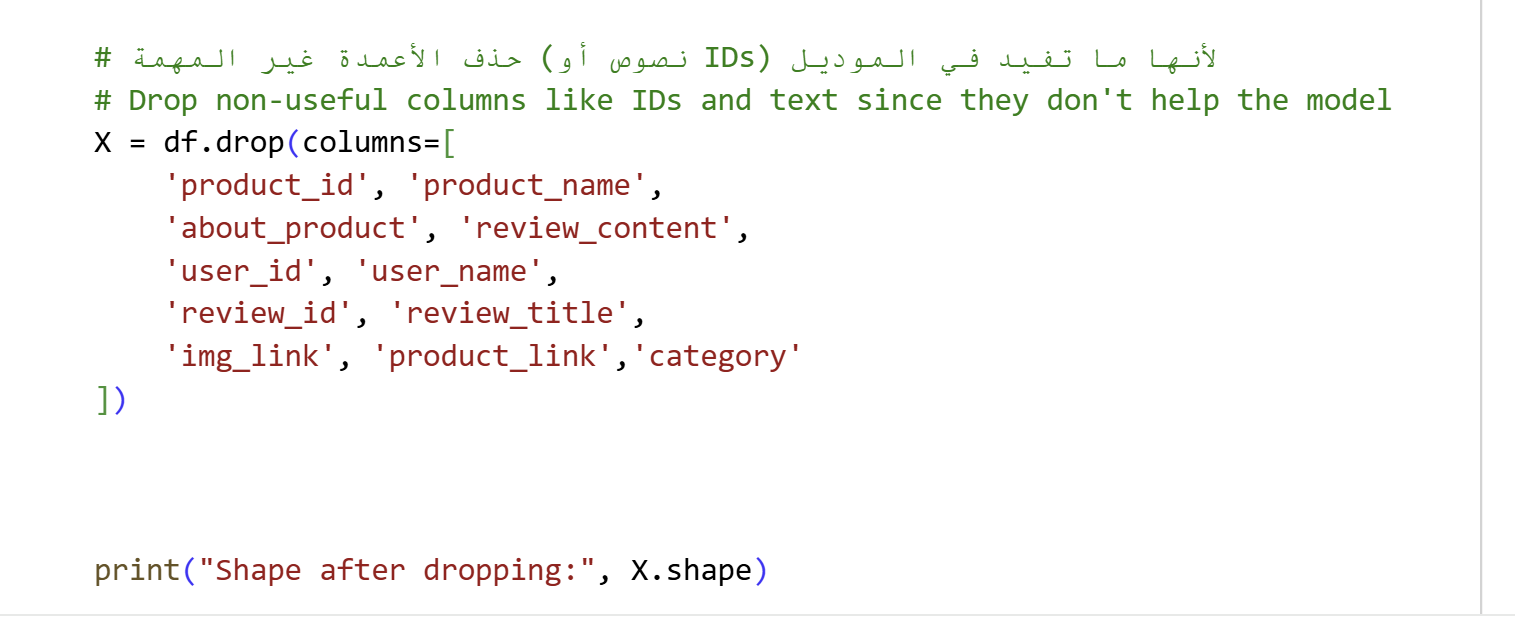

**▶What was removed, and why?**

The column actual_price was removed from the modeling dataset due to its strong correlation with discounted_price, which could cause multicollinearity and redundancy.

تم حذف عمود actual_price من بيانات النمذجة بسبب وجود ارتباط قوي مع discounted_price، مما قد يؤدي إلى تكرار المعلومات ومشكلة تعدد الترابط.


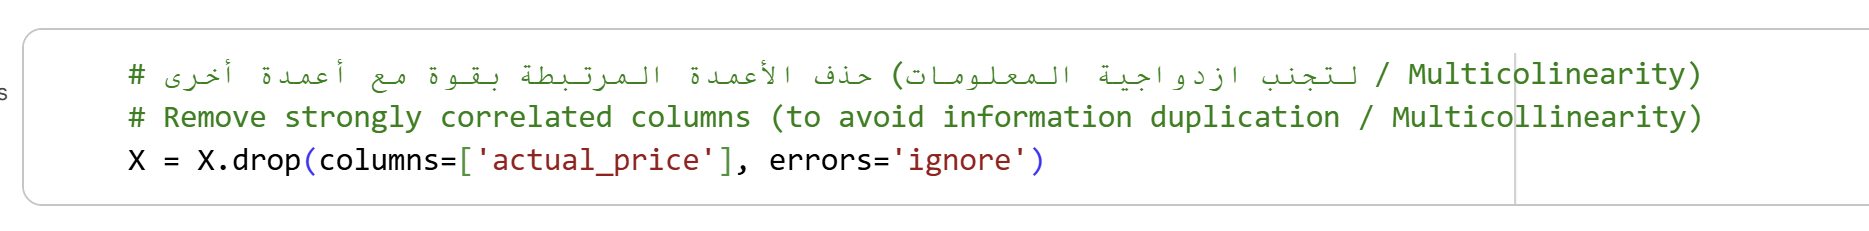

**▶What was removed, and why?**

Less important features were eliminated using RFE (Recursive Feature Elimination), reducing the number of features from 11 to 7 by keeping only the most relevant ones.

These steps helped reduce noise, eliminate redundancy, and simplify the dataset while retaining the most important information for modeling.

تم حذف الميزات الأقل أهمية باستخدام خوارزمية RFE، حيث تم تقليل عدد الميزات من 11 إلى 7 مع الاحتفاظ بالأكثر تأثيرًا فقط.

وقد ساعدت هذه الخطوات في تقليل الضوضاء، إزالة التكرار، وتبسيط البيانات مع الحفاظ على أهم المعلومات اللازمة للنمذجة.

**Output:**

Number of features before RFE: 11

Number of features after RFE: 7

Selected features:
['mid_category_Computers&Accessories', 'mid_category_Home&Kitchen', 'mid_category_OfficeProducts', 'mid_category_Electronics', 'mid_category_HomeImprovement', 'mid_category_Toys&Games', 'rating_credibility']



**▶What changed after cleaning?**

After the data cleaning and preprocessing steps, several important changes were observed in the dataset:

Missing values were handled, and the dataset no longer contains null values, ensuring data completeness.

Outliers were treated using the capping method, which reduced the impact of extreme values while preserving all records.

بعد عمليات تنظيف البيانات والمعالجة، حدثت عدة تغييرات مهمة في مجموعة البيانات:

تم معالجة القيم المفقودة، ولم تعد البيانات تحتوي على أي قيم ناقصة، مما يضمن اكتمال البيانات.

تم التعامل مع القيم الشاذة باستخدام طريقة Capping، مما قلل من تأثير القيم المتطرفة مع الحفاظ على جميع السجلات.

**Before:**

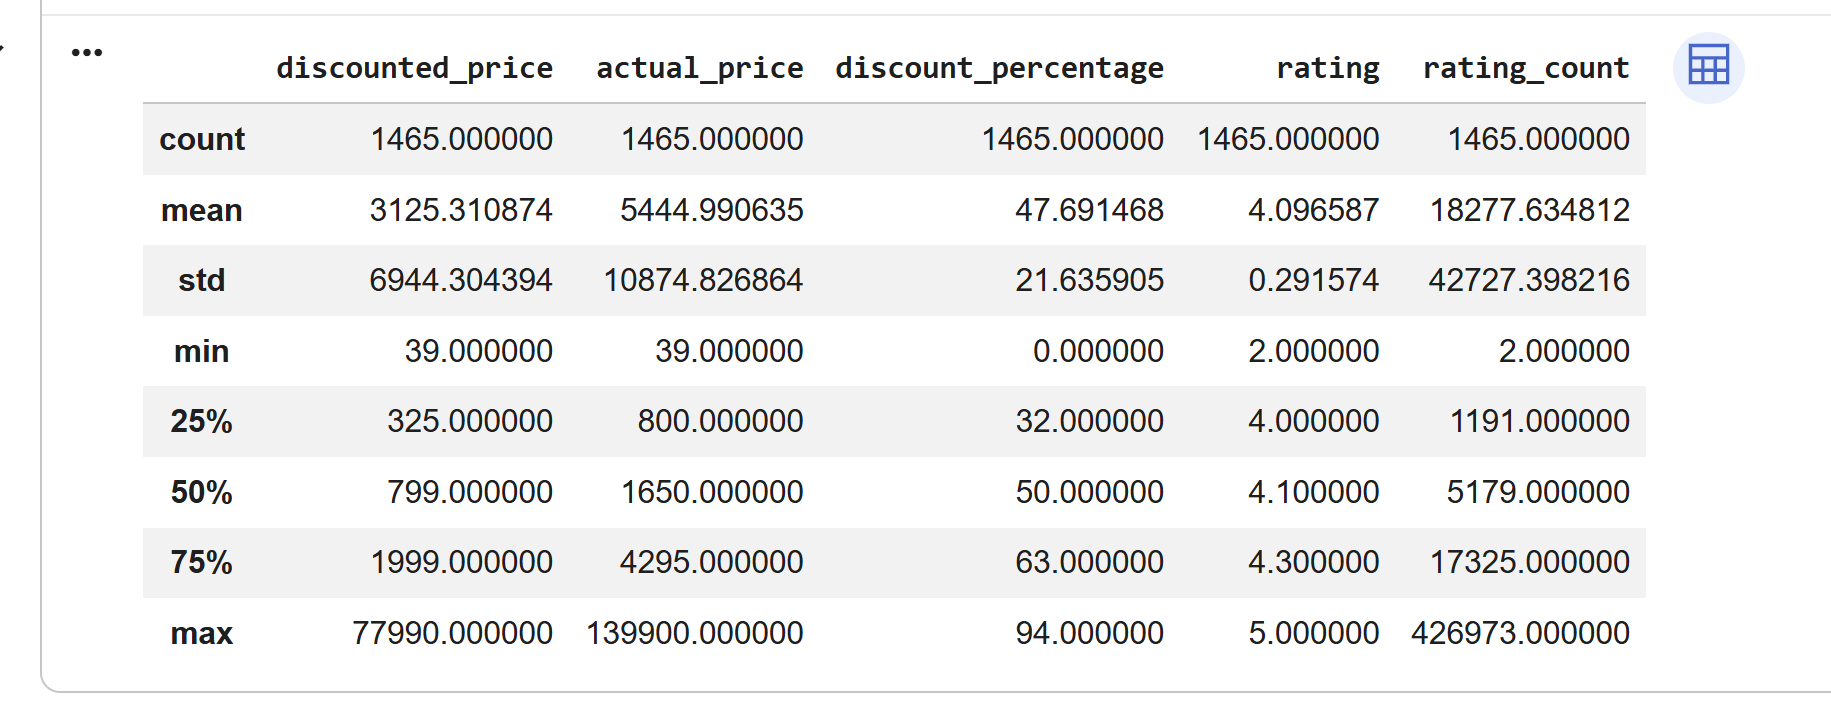

 **After:**

 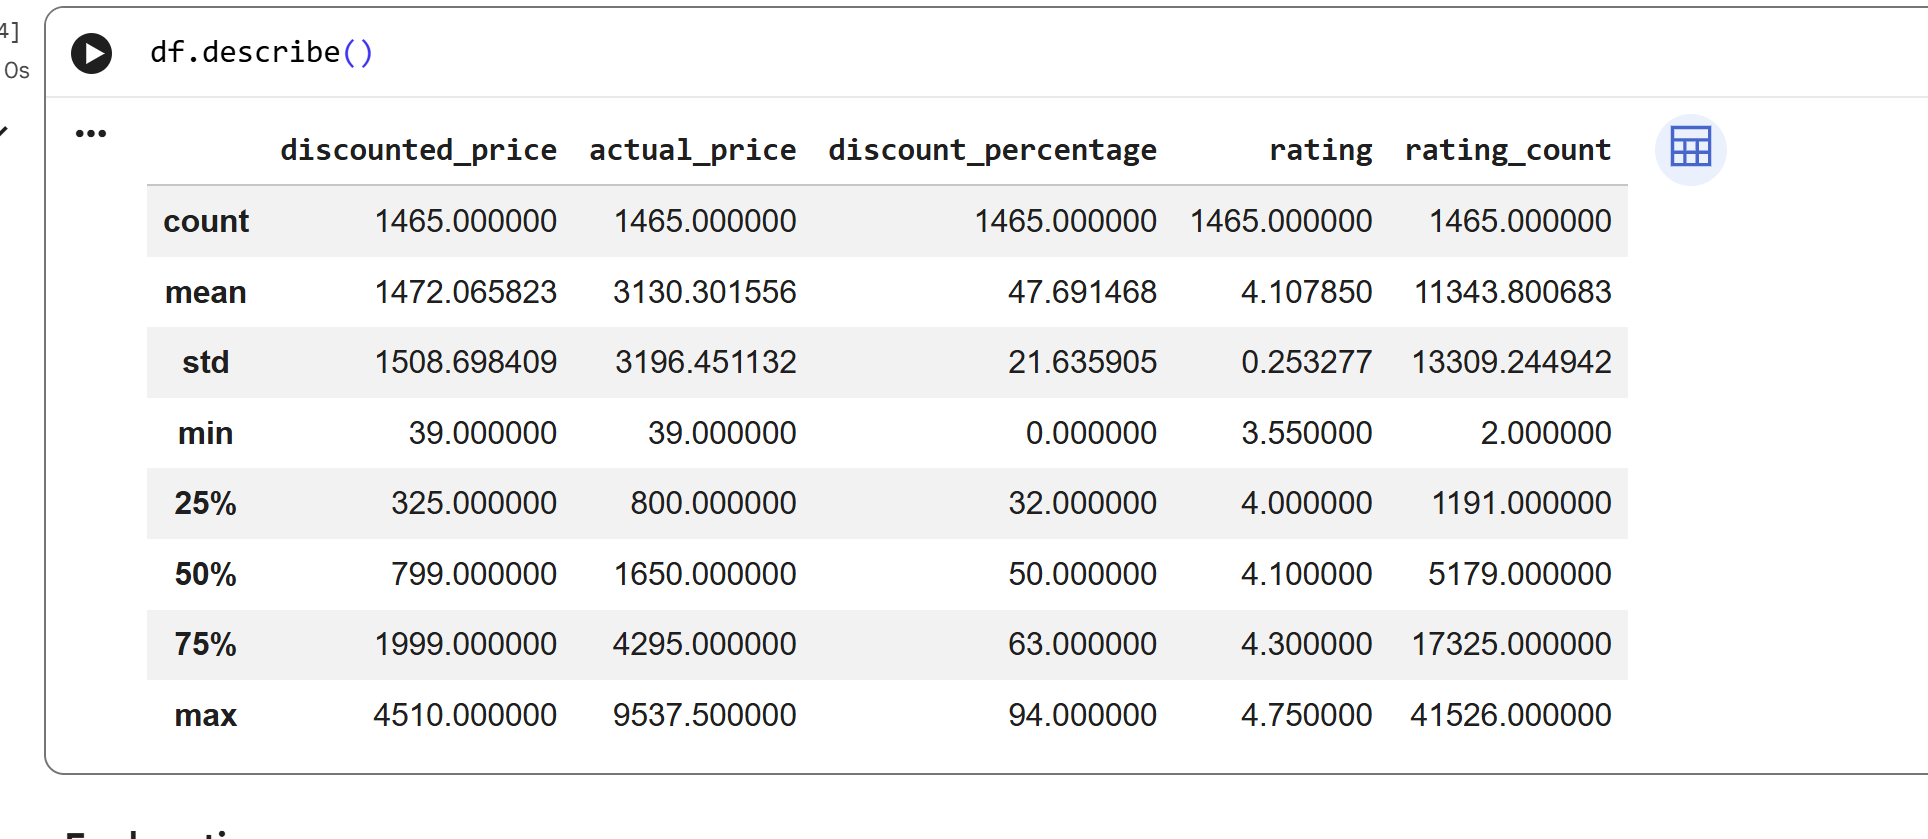


**Explanation:**

 Before handling outliers, the dataset contained extremely large values (such as prices and rating counts), which caused high mean and standard deviation and distorted the data distribution. After applying the capping method, these extreme values were reduced and brought within a reasonable range, resulting in lower variability and a more balanced dataset while preserving all data points.

 قبل معالجة القيم الشاذة، كانت البيانات تحتوي على قيم متطرفة كبيرة جدًا (مثل الأسعار وعدد التقييمات)، مما أدى إلى ارتفاع كبير في المتوسط والانحراف المعياري وتشويه توزيع البيانات. بعد تطبيق طريقة Capping، تم تقليل هذه القيم وجعلها ضمن نطاق منطقي، مما أدى إلى انخفاض التشتت وتحسين توازن البيانات مع الحفاظ على جميع السجلات دون حذف.

**▶What changed after cleaning?**

After cleaning, several columns that were originally stored as object (string) types were successfully converted into proper numerical formats (float and integer). This transformation ensured that numerical values such as prices, ratings, and counts are correctly represented and can be used in mathematical operations and machine learning models. As a result, the dataset became more consistent, accurate, and suitable for analysis.

بعد عملية التنظيف، تم تحويل عدد من الأعمدة التي كانت مخزنة سابقًا كـ object (نصوص) إلى صيغ رقمية صحيحة مثل float و int. وقد ساهم هذا التحويل في تمثيل القيم الرقمية مثل الأسعار والتقييمات بشكل دقيق، مما يتيح استخدامها في العمليات الحسابية ونماذج التعلم الآلي. ونتيجة لذلك، أصبحت البيانات أكثر اتساقًا ودقة
وجاهزة للتحليل.

Before:
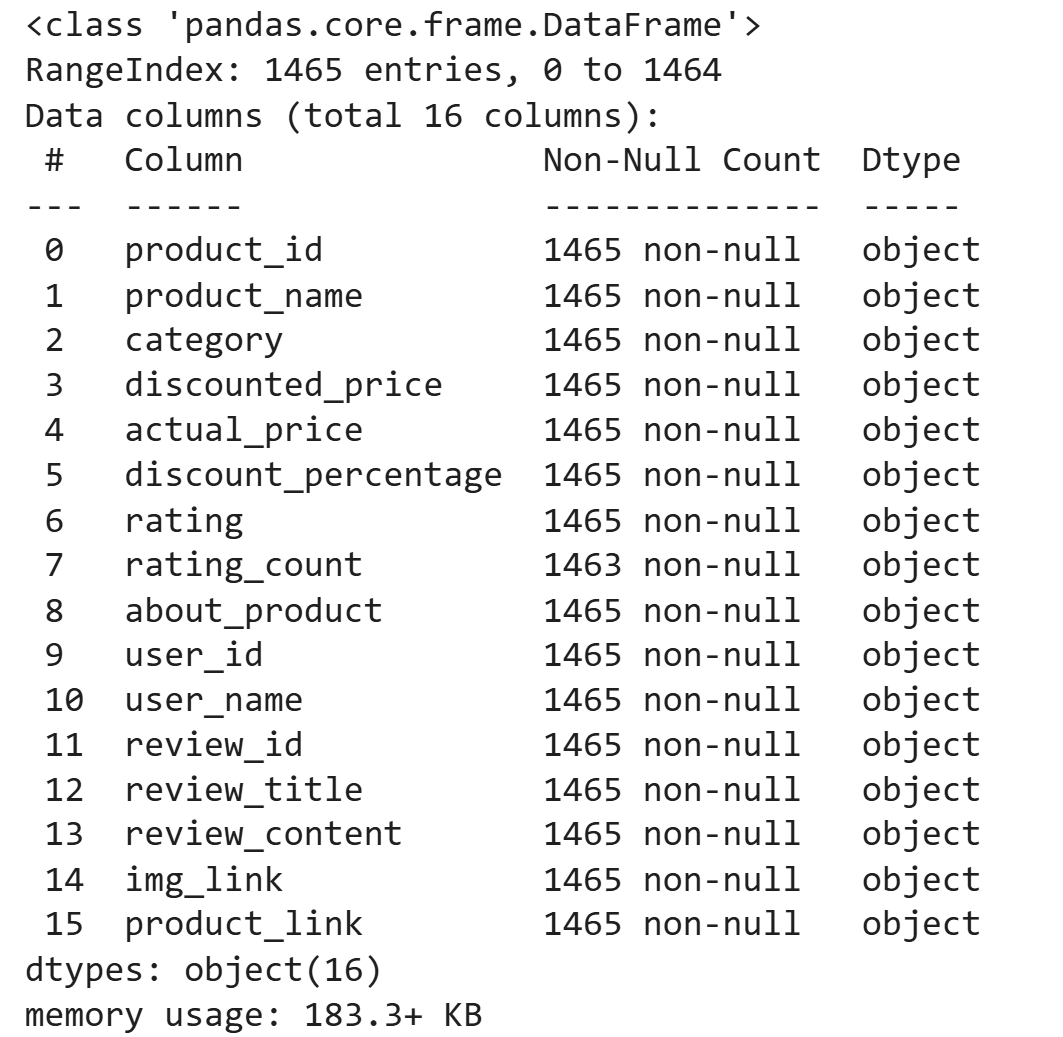


After:

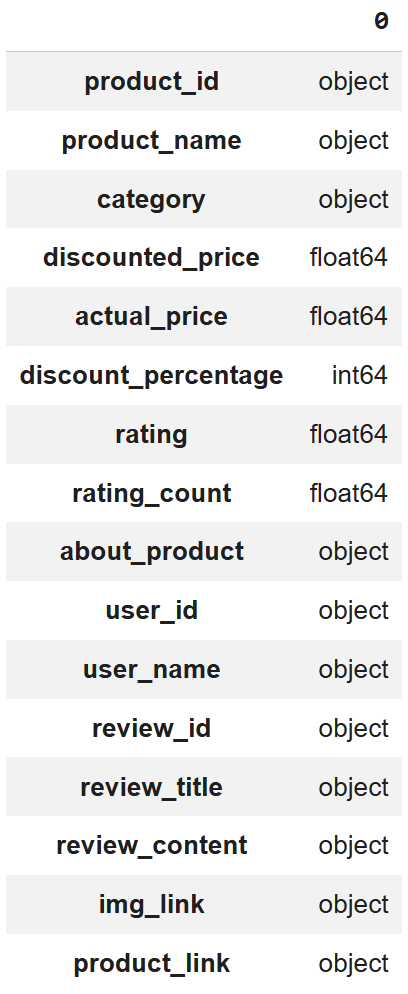

**▶What changed after cleaning?**


After cleaning, the missing values in the rating and rating_count columns were handled using median imputation. Previously, these columns contained missing values, which could negatively affect analysis and model performance. After applying the median, all missing values were filled, resulting in complete and consistent data without null entries.

بعد عملية التنظيف، تم معالجة القيم المفقودة في أعمدة rating و rating_count باستخدام الوسيط (Median). في السابق، كانت هذه الأعمدة تحتوي على قيم مفقودة قد تؤثر سلبًا على التحليل وأداء النموذج. وبعد تطبيق الوسيط، تم تعبئة جميع القيم المفقودة، مما أدى إلى بيانات مكتملة ومتسقة بدون أي قيم فارغة.


Before:

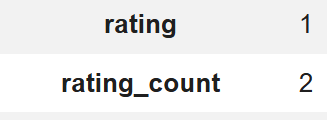


After:

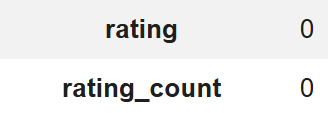



---

##**2.Key Statistical Results**

---





This section presents a statistical analysis of the dataset to understand the distribution and relationships between key variables such as discounted price, actual price, discount percentage, rating, and rating count.

Descriptive statistics show a wide variation in product prices and discount levels, indicating a diverse range of products. While prices vary significantly, customer ratings remain relatively stable and are mostly concentrated between 3.5 and 4.5.

The analysis also explores relationships between variables using visualizations such as scatter plots and correlation heatmaps. The results show that there is no strong relationship between price and rating, while there is a strong positive correlation between actual price and discounted price.

Overall, the analysis highlights that customer satisfaction is generally high and is not strongly affected by price or discount levels, but is more influenced by product popularity and review counts.



---

يقدم هذا القسم تحليلًا إحصائيًا للبيانات لفهم توزيع العلاقات بين المتغيرات مثل السعر بعد الخصم، السعر الأصلي، نسبة الخصم، التقييم، وعدد التقييمات.

تُظهر النتائج وجود تباين كبير في الأسعار ونسب الخصم، مما يعكس تنوع المنتجات. بينما تظل التقييمات مستقرة نسبيًا وتتركز غالبًا بين 3.5 و 4.5.

كما يوضح التحليل من خلال الرسوم البيانية أنه لا توجد علاقة قوية بين السعر والتقييم، بينما توجد علاقة ارتباط قوية بين السعر الأصلي والسعر بعد الخصم.

بشكل عام، يشير التحليل إلى أن رضا العملاء مرتفع ولا يتأثر بشكل كبير بالسعر أو الخصومات، بل يرتبط أكثر بشعبية المنتج وعدد التقييمات.



---


**2.1 Important Computed Results**


---



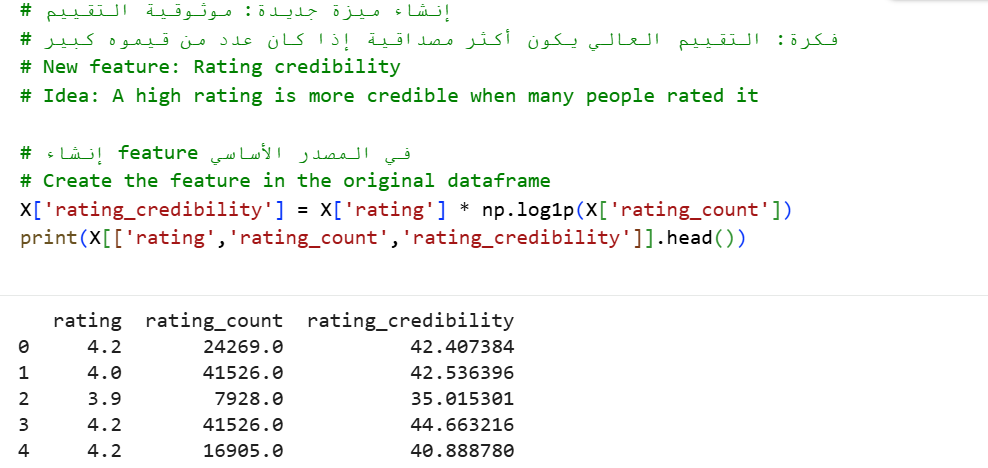

## Correlation Analysis

The rating values range approximately between 3.8 and 4.6, indicating that most products receive relatively high customer satisfaction scores.
However, the rating count varies significantly, ranging from a few thousand to over 40,000 ratings, which shows a large difference in how frequently products are reviewed.

For example, a product with a rating of 4.2 and 41,526 reviews has a credibility score of approximately 44.66, while another product with a similar rating of 4.2 but only 16,905 reviews has a lower credibility score of about 40.89.
This demonstrates that even when ratings are similar, the number of reviews strongly impacts the reliability of the evaluation.

The derived feature rating credibility effectively combines both rating and rating count, providing a more balanced and realistic measure of product quality.
## Insight

These results indicate that relying solely on rating can be misleading, as products with fewer reviews may appear equally good.
However, incorporating rating count through the credibility feature provides a more reliable indicator of true customer satisfaction.
Therefore, products with high ratings and a large number of reviews should be considered more trustworthy.


---


##التحليل
تتراوح قيم التقييم بين 3.8 و 4.6، مما يدل على أن معظم المنتجات تحظى بمستوى رضا مرتفع من العملاء.
لكن عدد التقييمات يختلف بشكل كبير، حيث يتراوح من بضعة آلاف إلى أكثر من 40,000 تقييم، وهذا يدل على تفاوت كبير في عدد الأشخاص الذين قاموا بتقييم المنتجات.

على سبيل المثال، منتج بتقييم 4.2 وعدد تقييمات 41,526 حصل على موثوقية تقريبًا 44.66،
بينما منتج آخر بنفس التقييم 4.2 ولكن بعدد تقييمات 16,905 حصل على موثوقية أقل تقريبًا 40.89.

وهذا يوضح أن عدد التقييمات له تأثير كبير حتى لو كان التقييم متقارب.


##الاستنتاج

تشير هذه النتائج إلى أن الاعتماد على التقييم فقط قد يكون مضللًا،
حيث قد تبدو المنتجات متشابهة في التقييم رغم اختلاف عدد المقيمين.

لكن عند استخدام متغير موثوقية التقييم (rating credibility)، نحصل على صورة أكثر دقة وواقعية عن جودة المنتج ورضا العملاء.

لذلك، المنتجات التي تمتلك تقييمًا مرتفعًا وعدد تقييمات كبير تعتبر أكثر موثوقي

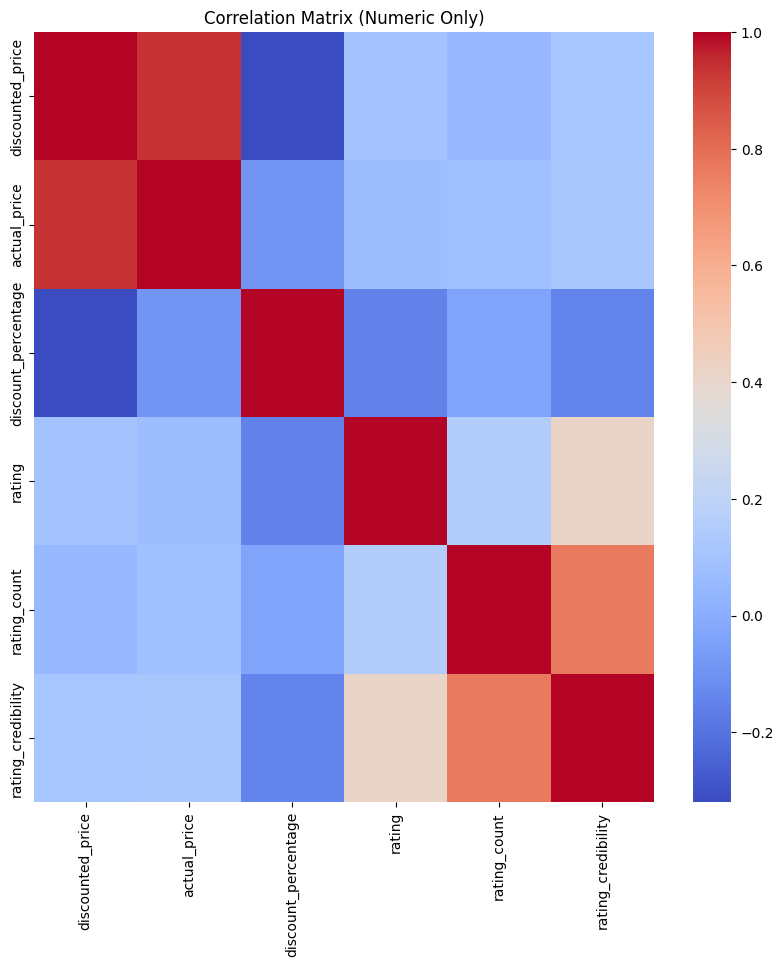

## Correlation Analysis

The correlation matrix shows the relationships between key numerical variables, including discounted price, actual price, discount percentage, rating, rating count, and rating credibility.

We observe a strong positive correlation between rating count and rating credibility, indicating that products with a higher number of reviews tend to have more reliable and trustworthy ratings. This is expected since the credibility feature combines both rating and the number of ratings.

There is also a clear positive correlation between actual price and discounted price, which suggests that products with higher original prices remain relatively expensive even after discounts.

On the other hand, the relationship between rating and discount percentage appears weak, indicating that higher discounts do not necessarily lead to higher customer satisfaction.

## Insight

These findings suggest that customer trust is influenced more by the number of reviews than the rating value alone. Additionally, pricing patterns remain consistent despite discounts, and discount strategies do not significantly impact customer ratings.


---

## التحليل

يوضح هذا الرسم العلاقات بين المتغيرات الرقمية مثل السعر بعد الخصم، السعر الأصلي، نسبة الخصم، التقييم، عدد التقييمات، وموثوقية التقييم.

نلاحظ وجود علاقة قوية موجبة بين عدد التقييمات وموثوقية التقييم، مما يدل على أن المنتجات التي لديها عدد تقييمات أكبر تكون أكثر موثوقية.

كما توجد علاقة موجبة بين السعر الأصلي والسعر بعد الخصم، مما يعني أن المنتجات ذات الأسعار المرتفعة تظل مرتفعة نسبيًا حتى بعد الخصم.

بينما العلاقة بين التقييم ونسبة الخصم ضعيفة، مما يشير إلى أن الخصومات لا تؤثر بشكل مباشر على تقييم العملاء.

##  الاستنتاج

تشير النتائج إلى أن موثوقية التقييم تعتمد بشكل أساسي على عدد التقييمات وليس فقط قيمة التقييم. كما أن الخصومات لا تؤثر بشكل واضح على رضا العملاء، بينما تبقى الأسعار مرتبطة بقيمتها الأصلية.

These computed results highlight key relationships and derived metrics that enhance the understanding of product performance beyond raw variables.

توضح هذه النتائج الإحصائية علاقات مهمة وتضيف متغيرات مشتقة تساعد في فهم أعمق لأداء المنتجات.



---


##### **2.2 Range of Key Variables**


---




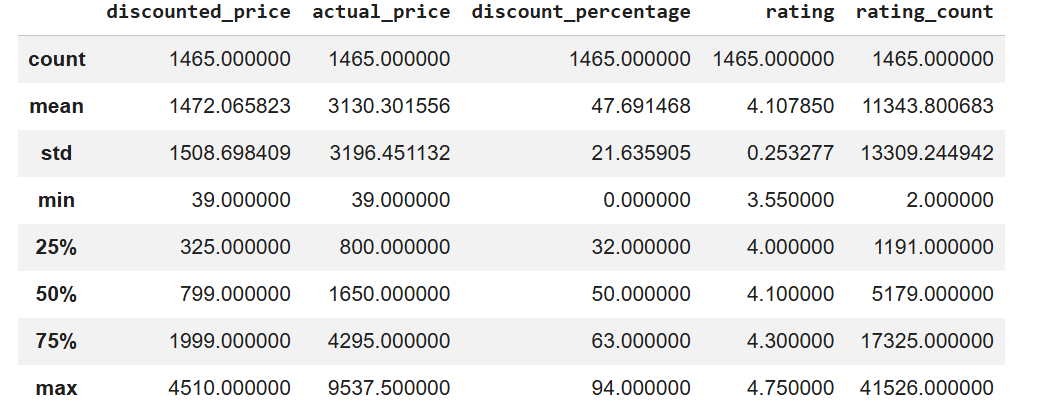

The statistical summary shows a wide variation in product prices, with discounted prices ranging from very low values to over 4,500, while actual prices reach above 9,500. This indicates a diverse range of products and pricing levels. The discount percentage also varies significantly, suggesting inconsistent discount strategies across products.

In contrast, ratings remain relatively stable, mostly between 3.5 and 4.75 with a high average, reflecting generally positive customer satisfaction. However, the rating count shows extreme variability, ranging from only a few reviews to tens of thousands, highlighting differences in product popularity and visibility.

## Insight:

 While pricing and discount levels vary widely, customer satisfaction remains consistently high. This suggests that ratings are not strongly influenced by price, whereas the number of reviews plays a more important role in determining product credibility and trust.


---



تُظهر الإحصائيات وجود تباين كبير في أسعار المنتجات، حيث تتراوح الأسعار بعد الخصم من قيم منخفضة إلى أكثر من 4500، بينما تصل الأسعار الأصلية إلى أكثر من 9500، مما يدل على تنوع واسع في المنتجات. كما تختلف نسب الخصم بشكل ملحوظ، مما يشير إلى عدم وجود سياسة خصومات موحدة.

في المقابل، تبقى التقييمات مستقرة نسبيًا وتتراوح غالبًا بين 3.5 و 4.75 بمتوسط مرتفع، مما يعكس رضا عام من العملاء. بينما يظهر عدد التقييمات تباينًا كبيرًا جدًا، من عدد قليل إلى عشرات الآلاف، مما يدل على اختلاف شعبية المنتجات.





##الاستنتاج :
 بالرغم من اختلاف الأسعار والخصومات، إلا أن رضا العملاء يبقى مرتفعًا، مما يعني أن السعر ليس العامل الأساسي في التقييم، بينما يلعب عدد التقييمات دورًا أكبر في تحديد موثوقية المنتج



---


### **2.3 Group-Based Results**


---





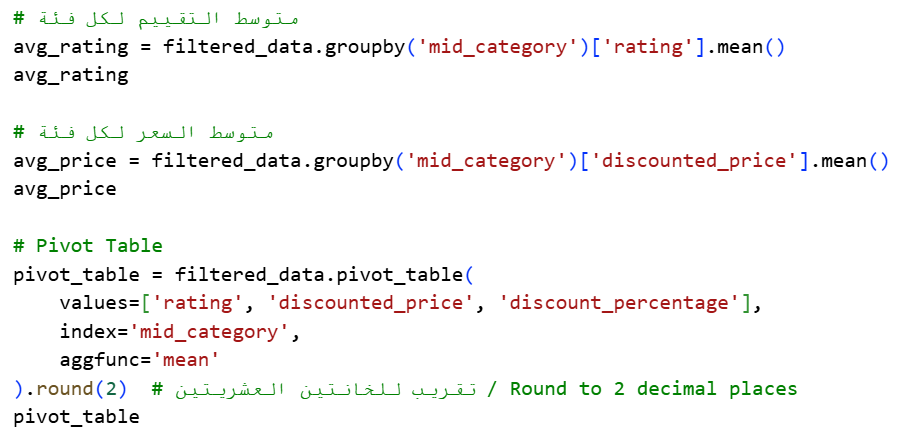

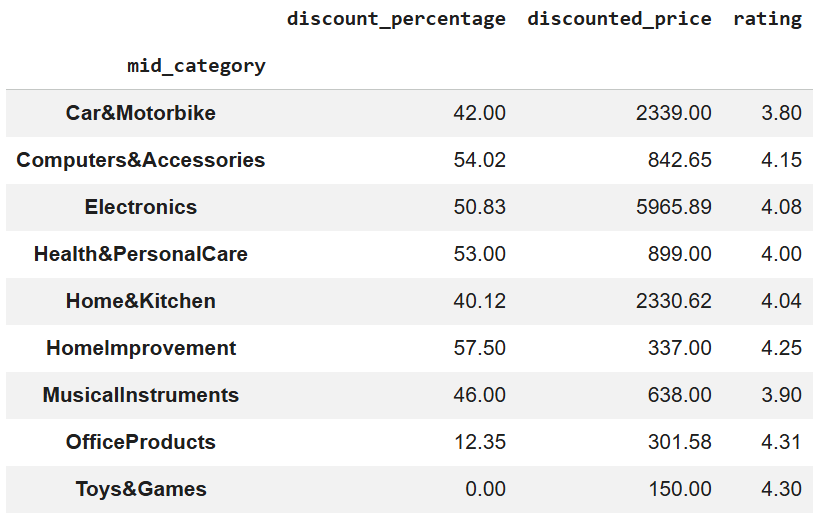

### Analysis
The aggregated results reveal clear differences between product categories in pricing, discount strategies, and customer ratings. Categories such as Electronics and Home & Kitchen tend to have higher average prices, while categories like Toys & Games and Office Products show lower price levels, indicating variation in product value across categories.

In terms of discounts, categories such as Home Improvement and Computers & Accessories offer relatively higher discount percentages, suggesting more aggressive pricing strategies. However, despite these variations, customer ratings remain relatively stable across most categories, generally ranging between 4.0 and 4.3, indicating that satisfaction is not strongly influenced by price differences.

### Insight
These findings suggest that customer satisfaction is not primarily driven by price or discount levels. Instead, factors such as product quality, brand reputation, and perceived value play a more significant role. Additionally, higher discounts do not necessarily lead to higher ratings, reinforcing that customer experience depends on more than just pricing strategies.


---


### التحليل
تُظهر النتائج المجمعة وجود اختلافات واضحة بين فئات المنتجات من حيث الأسعار ونسب الخصم والتقييمات. فئات مثل الإلكترونيات والمطبخ والمنزل تميل إلى امتلاك أسعار أعلى، بينما فئات مثل الألعاب ومنتجات المكتب تُظهر مستويات أسعار أقل، مما يعكس تنوعًا في قيمة المنتجات بين الفئات.

من ناحية الخصومات، تقدم بعض الفئات مثل تحسين المنزل والحواسيب نسب خصم أعلى، مما يشير إلى استراتيجيات تسعير أكثر تنافسية. ومع ذلك، وعلى الرغم من هذه الاختلافات، تبقى التقييمات متقاربة بين معظم الفئات، حيث تتراوح غالبًا بين 4.0 و 4.3، مما يدل على أن رضا العملاء لا يعتمد بشكل كبير على فروقات الأسعار.

### الاستنتاج
تشير هذه النتائج إلى أن رضا العملاء لا يعتمد بشكل أساسي على السعر أو نسبة الخصم، بل يتأثر بعوامل أخرى مثل جودة المنتج، سمعة العلامة التجارية، والقيمة المدركة. كما أن تقديم خصومات أعلى لا يعني بالضرورة الحصول على تقييمات أعلى، مما يؤكد أن تجربة العميل تعتمد على أكثر من مجرد السعر.



---


###**2.4 Most Frequent Categories**


---



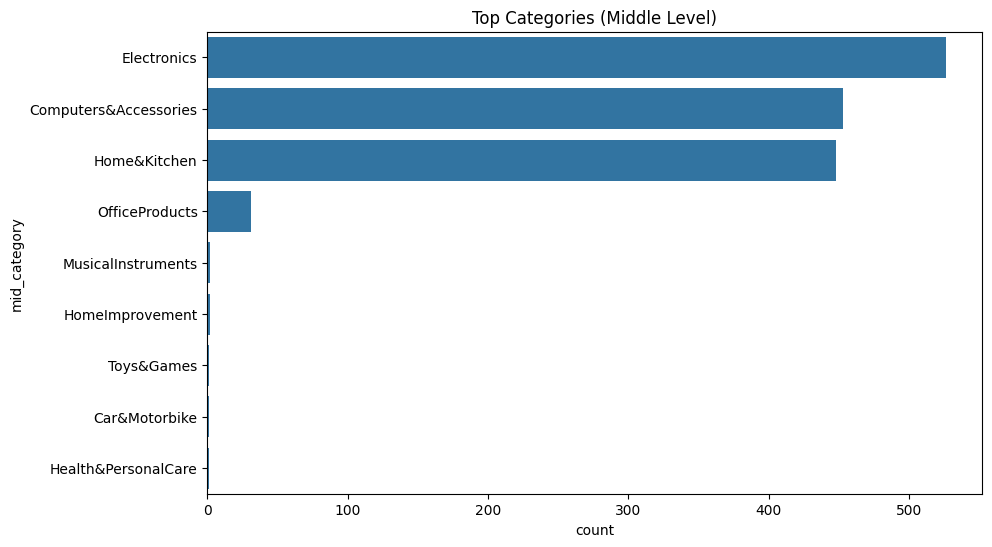

imbalance in category distribution
  
  
    يعني إن بعض الفئات (مثل Electronics) عندها عدد منتجات كبير جدًا
    بينما فئات ثانية عندها عدد قليل.
bias in the analysis
    
    
    يعني ممكن التحليل يكون متحيز بدون ما تنتبهين.

##  Top Categories Distribution (Bar Chart)

The bar chart shows that Electronics has the highest number of products, followed by Computers & Accessories and Home & Kitchen, while other categories have significantly fewer products.

###  Insight
The dataset is dominated by a few major categories, which may influence overall analysis and reflect higher demand in these segments.

---

##  توزيع الفئات

يوضح الرسم أن فئة الإلكترونيات هي الأكثر انتشارًا، تليها فئات مثل **الكمبيوتر والمطبخ**، بينما باقي الفئات أقل بكثير.

###  الاستنتاج
تركّز البيانات في فئات معينة قد يؤثر على نتائج التحليل ويعكس اهتمام العملاء بهذه الفئات بشكل أكبر.

### **2.5 Additional Insights**


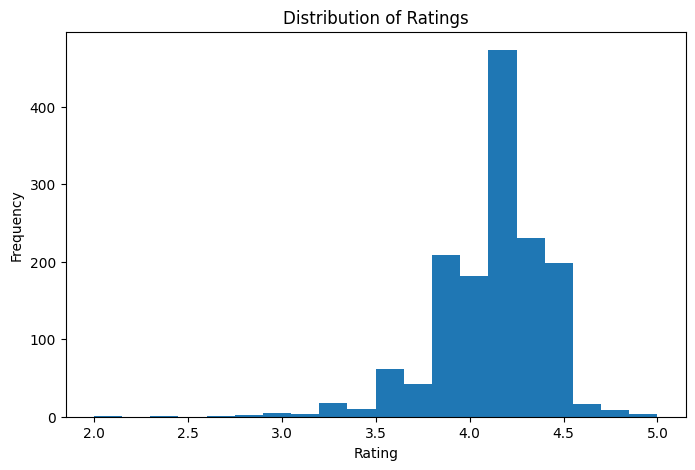

##  Distribution of Ratings (Histogram)

The histogram shows that most product ratings are concentrated between 4.0 and 4.5, with very few low ratings below 3.5. This indicates that the majority of products receive high customer satisfaction scores.

###  Insight
The high concentration of ratings suggests generally positive customer experiences, but the limited variation means that rating alone may not be enough to distinguish product quality.

---

## توزيع التقييمات

يوضح الرسم أن أغلب التقييمات تقع بين **4 و 4.5**، مع قلة في التقييمات المنخفضة، مما يدل على رضا مرتفع لدى العملاء.

###  الاستنتاج
ارتفاع التقييمات يدل على جودة عامة جيدة، لكن قلة التباين تعني أن التقييم وحده لا يكفي للمقارنة بين المنتجات.

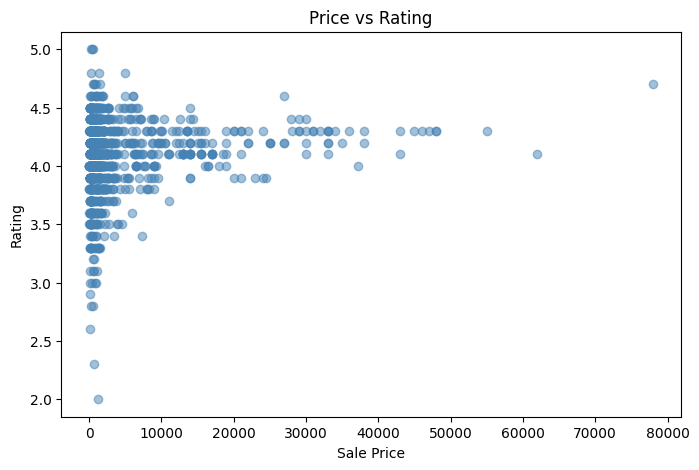

##  Price vs Rating Analysis (Scatter Plot)

The scatter plot illustrates the relationship between product price and customer ratings. The majority of data points are clustered between ratings of 3.5 and 4.5, regardless of price variation.

There is no clear linear relationship between price and rating, as both low-priced and high-priced products can achieve similarly high ratings. Additionally, most ratings remain concentrated in a narrow range even as prices increase significantly.

###  Insight
These results indicate that price is not a strong determinant of customer satisfaction. High-priced products do not necessarily receive higher ratings, suggesting that perceived value and product quality are influenced by factors other than price alone.

---

##  تحليل العلاقة بين السعر والتقييم

يوضح الرسم العلاقة بين السعر والتقييم، حيث تتركز أغلب القيم بين 3.5 و 4.5 بغض النظر عن اختلاف الأسعار.

ولا توجد علاقة واضحة بين السعر والتقييم، حيث يمكن أن تحصل المنتجات منخفضة السعر ومرتفعة السعر على تقييمات متقاربة.

###  الاستنتاج
تشير النتائج إلى أن **السعر لا يؤثر بشكل مباشر على رضا العملاء**، وأن جودة المنتج أو قيمته لا تعتمد فقط على كونه غالي أو رخيص.

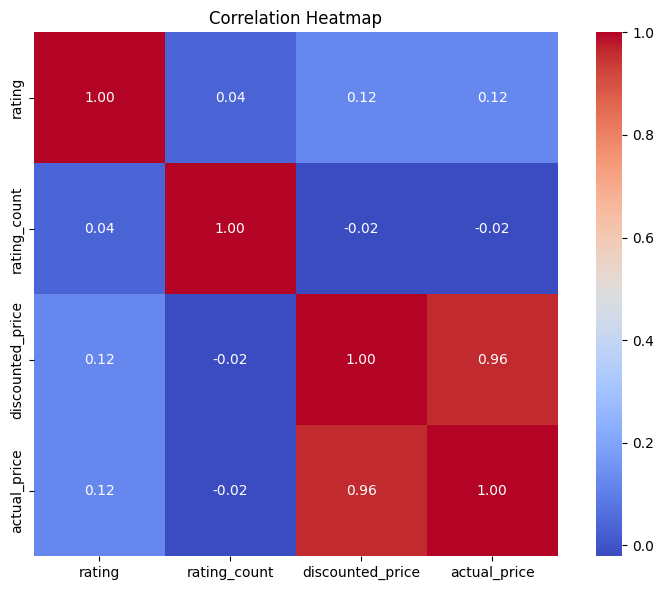

##  Correlation Heatmap

The heatmap shows a strong positive correlation (**≈ 0.96**) between actual price and discounted price, meaning that expensive products remain relatively expensive even after discounts.

The correlation between rating and rating count is very weak (≈ 0.04), indicating that highly rated products are not necessarily the most reviewed. Additionally, discount percentage has little impact on ratings.

###  Insight
Customer satisfaction is not strongly influenced by discounts, and rating reliability depends more on the number of reviews than the rating value itself.

---

##  تحليل الارتباط

يوضح الرسم وجود علاقة قوية بين السعر الأصلي والسعر بعد الخصم، مما يعني أن المنتجات مرتفعة السعر تبقى كذلك حتى بعد الخصومات.

كما أن العلاقة بين التقييم وعدد التقييمات ضعيفة جدًا، مما يدل على أن التقييم العالي لا يعني بالضرورة عدد تقييمات كبير.

###  الاستنتاج
تشير النتائج إلى أن الخصومات لا تؤثر بشكل واضح على رضا العملاء، وأن موثوقية التقييم تعتمد بشكل أكبر على عدد التقييمات.

Overall, the analysis shows that customer satisfaction is generally high, and factors like price and discounts have limited influence compared to product popularity and category.



بشكل عام، يظهر التحليل أن رضا العملاء مرتفع، وأن السعر والخصومات ليس لها تأثير كبير مقارنة بشعبية المنتج والفئة.



---


##**3. Final Inisghts (MOST IMPORTANT)**


---



**The overall analysis reveals a clear and consistent story about customer behavior, product pricing, and category distribution in the dataset.**

 ##### **• What is the main story in the data ?**

The main story of the dataset is that customer satisfaction is generally high across most products, but it is not strongly influenced by price or discount levels.

Instead, the reliability of ratings depends more on the number of reviews. Products with a high number of ratings are more trustworthy compared to products with similar rating values but fewer reviews.

Additionally, the dataset is dominated by a few major categories such as Electronics, Computers & Accessories, and Home & Kitchen, which may influence the overall analysis and introduce bias toward these categories.



تُظهر البيانات أن رضا العملاء مرتفع بشكل عام لمعظم المنتجات، لكنه لا يعتمد بشكل كبير على السعر أو نسبة الخصم.

بل تعتمد موثوقية التقييم بشكل أكبر على عدد التقييمات، حيث تكون المنتجات التي تمتلك عدد تقييمات أكبر أكثر مصداقية مقارنة بمنتجات لها نفس التقييم ولكن بعدد تقييمات أقل.

كما أن البيانات تتركز في عدد محدود من الفئات مثل الإلكترونيات وأجهزة الكمبيوتر والمطبخ، مما قد يؤثر على نتائج التحليل ويخلق نوعًا من التحيز.



##### **• What patterns or trends were discovered ?**

The analysis identified several important patterns:

- Most product ratings are concentrated between 4 and 5, indicating generally high customer satisfaction.
- There is a strong positive relationship between actual price and discounted price, showing that pricing structure remains consistent even after discounts.
- There is no strong relationship between product price and customer ratings, meaning expensive products are not necessarily rated higher.
- The number of reviews varies significantly across products, which directly affects the reliability of ratings.
- Aggregation results show clear differences between categories in terms of pricing, discount strategies, and average ratings.
- The distribution of products is imbalanced, with a few dominant categories containing most of the data.



أظهر التحليل عدة أنماط مهمة:

- تتركز أغلب التقييمات بين 4 و 5، مما يدل على رضا عام مرتفع.
- توجد علاقة قوية بين السعر الأصلي والسعر بعد الخصم، مما يدل على ثبات هيكل التسعير.
- لا توجد علاقة قوية بين السعر والتقييم، مما يعني أن المنتجات الأغلى ليست بالضرورة الأعلى تقييمًا.
- يوجد تفاوت كبير في عدد التقييمات، وهذا يؤثر بشكل مباشر على موثوقية التقييم.
- أظهرت نتائج التجميع اختلافات واضحة بين الفئات من حيث الأسعار والتقييمات ونسب الخصم.
- توزيع البيانات غير متوازن، حيث تتركز أغلب المنتجات في عدد محدود من الفئات.

##### **•  What is the most important conclusion supported by data ?**

The most important conclusion is that customer satisfaction is not primarily driven by price or discount levels.

Instead, product performance is more strongly influenced by category characteristics, product popularity, and the number of reviews.

This means that relying only on rating values can be misleading, and incorporating rating credibility (which combines rating and review count) provides a more accurate and reliable measure of product quality.

أهم استنتاج هو أن رضا العملاء لا يعتمد بشكل أساسي على السعر أو الخصومات.

بل يتأثر أداء المنتج بشكل أكبر بعوامل مثل الفئة، وشعبية المنتج، وعدد التقييمات.

كما أن الاعتماد على التقييم فقط قد يكون مضللًا، لذلك فإن استخدام مقياس موثوقية التقييم (rating credibility) يعطي صورة أدق عن جودة المنتج.